# 03 · UHI index model: bilinear-resampling experiment

An experiment from the competition, kept as it was run. It predates the `uhi` package, so its code is inline; the package offers the same building blocks (for example `uhi.features.spatial.map_idw` for the inverse-distance-weighted mapping).

It is a variant of the pipeline in `02_uhi_model_nearest.ipynb`. The differences:

| Step | 02 (final submission) | 03 (this notebook) |
|---|---|---|
| Resampling onto the 10 m grid | nearest neighbour | bilinear |
| Radius of the building statistics | 500 m | 100 m |
| Extra feature | – | `NDVI_Building_Ratio` |
| Features with a 100 m focal mean | 52 pixel features + 12 building features | 52 pixel features + 5 MODIS composites |
| Focal computation | `dask.delayed` | local Dask cluster (4 workers) |
| Features of each point | nearest pixel (`sjoin_nearest`) | inverse-distance-weighted mean of the 5 nearest pixels (`mapped_*` columns) |

The notebook stops after feature selection; see **Outcome** at the end.
To regenerate its inputs, run `01_satellite_data_extraction.ipynb` with `RESAMPLING = Resampling.bilinear`.

> Saved outputs come from the original competition run.

## 0. Setup

In [ ]:
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
import numpy as np
import pandas as pd

# Multi-dimensional arrays and datasets
import xarray as xr

# Geospatial raster data handling
import rioxarray as rxr

# Geospatial data analysis
import geopandas as gpd

# Geospatial operations
import rasterio
from rasterio import windows
from rasterio import features
from rasterio import warp
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds

# Image Processing
from PIL import Image

# Coordinate transformations
from pyproj import Proj, Transformer, CRS

# Feature Engineering
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Machine Learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split, cross_val_score,KFold
from sklearn.feature_selection import SelectKBest, f_regression,RFE,RFECV
from xgboost import XGBRegressor

# Planetary Computer Tools
import pystac_client
import planetary_computer as pc
from pystac.extensions.eo import EOExtension as eo

# Others
import os
import math
import time
from pathlib import Path
from tqdm import tqdm

import dask.array as da
from dask.diagnostics import ProgressBar

import gc

In [ ]:
# Project folders (relative to the notebooks/ directory)
RAW_DIR = Path("../data/raw")              # files provided by the challenge
PROCESSED_DIR = Path("../data/processed")  # GeoTIFFs written by 01_satellite_data_extraction.ipynb
OUTPUT_DIR = Path("../outputs")            # submission files

# Set to True to plot every band of the GeoTIFFs (slow and memory hungry)
SHOW_BAND_PLOTS = False

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_colwidth', 50)

## 1. Ground truth

In [3]:
# Training data: UHI index measured at 11,229 points on 24 July 2021 between 15:00 and 16:00
uhi_path = RAW_DIR / "Training_data_uhi_index_UHI2025-v2.csv"

ground_df = pd.read_csv(uhi_path)
ground_df.head()

,Longitude,Latitude,datetime,UHI Index
0,-73.909167,40.813107,24-07-2021 15:53,1.030289
1,-73.909187,40.813045,24-07-2021 15:53,1.030289
2,-73.909215,40.812978,24-07-2021 15:53,1.023798
3,-73.909242,40.812908,24-07-2021 15:53,1.023798
4,-73.909257,40.812845,24-07-2021 15:53,1.021634


## 2. Satellite features
All GeoTIFFs share the same 1448 × 1671 grid of 10 m pixels. Each file is flattened into a DataFrame with one row per pixel in the same (row-major) order, so the DataFrames can simply be concatenated side by side.

### Helper functions

In [ ]:
# Band names, in the order in which 01_satellite_data_extraction.ipynb writes them
S2_BANDS = ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08',
            'B8A', 'B09', 'B11', 'B12', 'AOT', 'WVP', 'visual', 'SCL']
LANDSAT_BANDS = ['red', 'green', 'blue', 'nir08', 'swir16', 'swir22', 'coastal',
                 'emis', 'emsd', 'trad', 'urad', 'atran', 'cdist', 'lwir11']
MODIS_LST_BANDS = ['LST', 'Emis_31', 'Emis_32']
MODIS_VI_BANDS = ['NDVI', 'EVI']

# Longer labels for the Sentinel-2 band plots
S2_BAND_LABELS = [
    "B01 - Coastal Aerosol", "B02 - Blue", "B03 - Green", "B04 - Red",
    "B05 - Red Edge 1", "B06 - Red Edge 2", "B07 - Red Edge 3", "B08 - NIR",
    "B8A - NIR Narrow", "B09 - Water Vapor", "B11 - SWIR 1", "B12 - SWIR 2",
    "AOT - Aerosol Optical Thickness", "WVP - Water Vapour Product",
    "Visual - True Color Image", "SCL - Scene Classification Map",
]


def extract_bands(tiff_path, band_names):
    """
    Read every band of a GeoTIFF into a DataFrame with one row per pixel.

    Parameters:
      - tiff_path: path to the GeoTIFF
      - band_names: column names in band order (any extra band is named "Band_<n>")

    Returns:
      - df: DataFrame of shape (height * width, n_bands), pixels in row-major order
    """
    with rasterio.open(tiff_path) as src:
        # All bands, shape (bands, height, width)
        bands_data = src.read()

    # Flatten every band to a 1-D array, shape (bands, height * width)
    bands_flat = bands_data.reshape(bands_data.shape[0], -1)

    df = pd.DataFrame({})
    for i in range(bands_data.shape[0]):
        col_name = band_names[i] if i < len(band_names) else f'Band_{i+1}'
        df[col_name] = bands_flat[i]
    return df


def extract_coordinates(tiff_path):
    """
    Longitude / latitude of every pixel centre of a GeoTIFF, in the same
    row-major order as extract_bands().
    """
    with rasterio.open(tiff_path) as src:
        transform = src.transform
        height, width = src.height, src.width

    # Grid of row / column indices, converted to map coordinates (EPSG:4326)
    rows, cols = np.meshgrid(np.arange(height), np.arange(width), indexing='ij')
    xs, ys = rasterio.transform.xy(transform, rows, cols)
    xs = np.array(xs).flatten()
    ys = np.array(ys).flatten()

    return pd.DataFrame({'Longitude': xs, 'Latitude': ys})


def plot_bands(tiff_path, band_labels, cmap='viridis', n_cols=3):
    """Plot every band of a GeoTIFF on a grid of subplots (n_cols per row)."""
    with rasterio.open(tiff_path) as src:
        band_data = [src.read(i + 1) for i in range(len(band_labels))]

    n_plots = len(band_data)
    n_rows = math.ceil(n_plots / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 4))
    axes = np.atleast_1d(axes).flatten()

    for ax, data, label in zip(axes, band_data, band_labels):
        im = ax.imshow(data, cmap=cmap)
        ax.set_title(label, fontsize=10)
        fig.colorbar(im, ax=ax)

    # Hide the unused subplots
    for ax in axes[n_plots:]:
        ax.axis("off")

    plt.tight_layout()
    plt.subplots_adjust(hspace=0.3, wspace=0.3)
    plt.show()

### Sentinel-2 (single day and median)

In [ ]:
st2_single_tiff_path = PROCESSED_DIR / "Sentinel2_SingleDay_bilinear.tiff"
st2_median_tiff_path = PROCESSED_DIR / "Sentinel2_Median_bilinear.tiff"

# Optional: plot every band
if SHOW_BAND_PLOTS:
    plot_bands(st2_single_tiff_path, S2_BAND_LABELS)
    plot_bands(st2_median_tiff_path, S2_BAND_LABELS)

In [6]:
st2_single_all = extract_bands(st2_single_tiff_path, S2_BANDS)
st2_single_all = st2_single_all.add_suffix("_single")  # suffix marks the single-day bands
st2_single_all.head()

,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single
0,692.0,639.0,728.0,839.0,1080.0,1933.0,1983.0,1440.0,2265.0,2330.0,1580.0,1110.0,163.0,1795.0,86.0,4.0
1,718.0,639.0,728.0,839.0,1032.0,1908.0,2040.0,1440.0,2237.0,2357.0,1572.0,1086.0,163.0,1795.0,86.0,4.0
2,745.0,395.0,579.0,415.0,937.0,1857.0,2155.0,2354.0,2182.0,2384.0,1555.0,1037.0,163.0,1839.0,43.0,4.0
3,771.0,562.0,775.0,688.0,947.0,1786.0,2129.0,2270.0,2119.0,2411.0,1588.0,1079.0,163.0,1839.0,70.0,4.0
4,797.0,919.0,1036.0,1108.0,1064.0,1696.0,1964.0,1584.0,2050.0,2438.0,1671.0,1212.0,163.0,1839.0,113.0,5.0


In [7]:
st2_single_all.shape

(2419608, 16)

In [8]:
st2_median_all = extract_bands(st2_median_tiff_path, S2_BANDS)
st2_median_all = st2_median_all.add_suffix("_median")  # suffix marks the median bands
st2_median_all.head()

,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median
0,728.572917,703.0,848.0,850.0,1107.75000,2012.50000,2247.62500,2020.0,2480.62500,2605.354167,1765.2500,1216.87500,150.5,2836.5,87.0,4.25000
1,753.010417,703.0,848.0,850.0,1103.81250,2008.06250,2275.43750,2020.0,2443.84375,2607.868056,1771.7500,1242.09375,150.5,2836.5,87.0,4.18750
2,777.447917,644.5,810.5,793.0,1095.93750,1999.18750,2331.06250,2360.0,2370.28125,2610.381944,1784.7500,1292.53125,150.5,2927.5,81.0,4.06250
3,801.885417,751.0,917.5,926.0,1169.78125,1960.53125,2253.09375,2490.0,2256.12500,2612.895833,1850.6875,1376.25000,150.5,2927.5,94.5,4.21875
4,826.322917,966.0,1016.0,1041.5,1325.34375,1892.09375,2041.53125,1567.0,2101.37500,2615.409722,1969.5625,1493.25000,150.5,2836.5,106.5,4.65625


In [9]:
st2_median_all.shape

(2419608, 16)

### Landsat 8 (single scene and median)

In [ ]:
lst_single_tiff_path = PROCESSED_DIR / "LST_Singleday_bilinear_4.tiff"
lst_median_tiff_path = PROCESSED_DIR / "LST_Median_bilinear_4.tiff"

# Optional: plot every band
if SHOW_BAND_PLOTS:
    plot_bands(lst_single_tiff_path, LANDSAT_BANDS)
    plot_bands(lst_median_tiff_path, LANDSAT_BANDS)

In [12]:
lst_single_all = extract_bands(lst_single_tiff_path, LANDSAT_BANDS)
lst_single_all = lst_single_all.add_suffix("_single")
lst_single_all.head()

,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single
0,0.072113,0.072837,0.048921,0.225407,0.152724,0.104865,0.045062,0.965233,0.010700,9.941333,1.038,0.8501,2.316667,34.329915
1,0.077726,0.077090,0.055567,0.222635,0.159929,0.113347,0.050436,0.969444,0.009256,9.933111,1.038,0.8501,2.326667,34.329915
2,0.083339,0.081343,0.062212,0.219864,0.167134,0.121829,0.055811,0.973656,0.007811,9.924889,1.038,0.8501,2.336667,34.329915
3,0.088952,0.085597,0.068858,0.217093,0.174339,0.130312,0.061186,0.977867,0.006367,9.916667,1.038,0.8501,2.346667,34.329915
4,0.106008,0.103799,0.077906,0.223005,0.202493,0.142769,0.069063,0.977156,0.006367,9.906000,1.038,0.8501,2.355556,34.329915


In [13]:
lst_single_all.shape

(2419608, 14)

In [14]:
lst_median_all = extract_bands(lst_median_tiff_path, LANDSAT_BANDS)
lst_median_all = lst_median_all.add_suffix("_median")
lst_median_all.head()

,red_median,green_median,blue_median,nir08_median,swir16_median,swir22_median,coastal_median,emis_median,emsd_median,trad_median,urad_median,atran_median,cdist_median,lwir11_median
0,0.075220,0.077278,0.055168,0.241210,0.163408,0.109696,0.047647,0.962933,0.010700,9.941167,3.257,0.6133,2.301667,34.066728
1,0.081461,0.082915,0.060295,0.237551,0.171070,0.117628,0.052337,0.965278,0.009256,9.932722,3.257,0.6133,2.311667,34.066728
2,0.087702,0.088553,0.065422,0.233892,0.178732,0.125560,0.057027,0.967622,0.007811,9.924278,3.257,0.6133,2.321667,34.066728
3,0.093943,0.094190,0.070550,0.230233,0.186393,0.133492,0.061717,0.969967,0.006367,9.915833,3.257,0.6133,2.331667,34.066728
4,0.109810,0.110244,0.079985,0.235446,0.211785,0.145926,0.070831,0.969967,0.006367,9.905222,3.257,0.6133,2.341111,34.066728


In [15]:
lst_median_all.shape

(2419608, 14)

### MODIS LST / emissivity and vegetation indices

In [ ]:
lst_mean_tiff_path = PROCESSED_DIR / "LST_Emis_mean_bilinear_8.tiff"
vi_mean_tiff_path = PROCESSED_DIR / "VI_mean_bilinear_9.tiff"

# Optional: plot every band
if SHOW_BAND_PLOTS:
    plot_bands(lst_mean_tiff_path, MODIS_LST_BANDS, cmap='magma')
    plot_bands(vi_mean_tiff_path, MODIS_VI_BANDS)

In [18]:
lst_mean_data = extract_bands(lst_mean_tiff_path, MODIS_LST_BANDS)
lst_mean_data = lst_mean_data.add_suffix("_mean")
lst_mean_data.head()

,LST_mean,Emis_31_mean,Emis_32_mean
0,32.09,0.48,0.486
1,32.09,0.48,0.486
2,32.09,0.48,0.486
3,32.09,0.48,0.486
4,32.09,0.48,0.486


In [21]:
vi_mean_data = extract_bands(vi_mean_tiff_path, MODIS_VI_BANDS)
vi_mean_data = vi_mean_data.add_suffix("_mean")
vi_mean_data.head()

,NDVI_mean,EVI_mean
0,0.656208,0.430977
1,0.655184,0.432610
2,0.654159,0.434242
3,0.653135,0.435875
4,0.652110,0.437508


In [23]:
# Pixel coordinates (every GeoTIFF shares the same grid)
coordinates = extract_coordinates(lst_single_tiff_path)
coordinates.head()

,Longitude,Latitude
0,-74.009955,40.879955
1,-74.009865,40.879955
2,-74.009776,40.879955
3,-74.009686,40.879955
4,-74.009596,40.879955


### Combine all satellite layers

In [24]:
# Combine two datasets side by side (column-wise) with pandas concat.
def combine_two_datasets(dataset1,dataset2):
    """
    Returns the two datasets concatenated column-wise.
    Attributes:
    dataset1 - Dataset 1 to be combined
    dataset2 - Dataset 2 to be combined
    """

    data = pd.concat([dataset1,dataset2], axis=1)
    return data

In [25]:
st2_data = combine_two_datasets(st2_single_all,st2_median_all)
st2_data.head()

,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median
0,692.0,639.0,728.0,839.0,1080.0,1933.0,1983.0,1440.0,2265.0,2330.0,1580.0,1110.0,163.0,1795.0,86.0,4.0,728.572917,703.0,848.0,850.0,1107.75000,2012.50000,2247.62500,2020.0,2480.62500,2605.354167,1765.2500,1216.87500,150.5,2836.5,87.0,4.25000
1,718.0,639.0,728.0,839.0,1032.0,1908.0,2040.0,1440.0,2237.0,2357.0,1572.0,1086.0,163.0,1795.0,86.0,4.0,753.010417,703.0,848.0,850.0,1103.81250,2008.06250,2275.43750,2020.0,2443.84375,2607.868056,1771.7500,1242.09375,150.5,2836.5,87.0,4.18750
2,745.0,395.0,579.0,415.0,937.0,1857.0,2155.0,2354.0,2182.0,2384.0,1555.0,1037.0,163.0,1839.0,43.0,4.0,777.447917,644.5,810.5,793.0,1095.93750,1999.18750,2331.06250,2360.0,2370.28125,2610.381944,1784.7500,1292.53125,150.5,2927.5,81.0,4.06250
3,771.0,562.0,775.0,688.0,947.0,1786.0,2129.0,2270.0,2119.0,2411.0,1588.0,1079.0,163.0,1839.0,70.0,4.0,801.885417,751.0,917.5,926.0,1169.78125,1960.53125,2253.09375,2490.0,2256.12500,2612.895833,1850.6875,1376.25000,150.5,2927.5,94.5,4.21875
4,797.0,919.0,1036.0,1108.0,1064.0,1696.0,1964.0,1584.0,2050.0,2438.0,1671.0,1212.0,163.0,1839.0,113.0,5.0,826.322917,966.0,1016.0,1041.5,1325.34375,1892.09375,2041.53125,1567.0,2101.37500,2615.409722,1969.5625,1493.25000,150.5,2836.5,106.5,4.65625


In [26]:
lst_data = combine_two_datasets(lst_single_all,lst_median_all)
lst_data.head()

,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,blue_median,nir08_median,swir16_median,swir22_median,coastal_median,emis_median,emsd_median,trad_median,urad_median,atran_median,cdist_median,lwir11_median
0,0.072113,0.072837,0.048921,0.225407,0.152724,0.104865,0.045062,0.965233,0.010700,9.941333,1.038,0.8501,2.316667,34.329915,0.075220,0.077278,0.055168,0.241210,0.163408,0.109696,0.047647,0.962933,0.010700,9.941167,3.257,0.6133,2.301667,34.066728
1,0.077726,0.077090,0.055567,0.222635,0.159929,0.113347,0.050436,0.969444,0.009256,9.933111,1.038,0.8501,2.326667,34.329915,0.081461,0.082915,0.060295,0.237551,0.171070,0.117628,0.052337,0.965278,0.009256,9.932722,3.257,0.6133,2.311667,34.066728
2,0.083339,0.081343,0.062212,0.219864,0.167134,0.121829,0.055811,0.973656,0.007811,9.924889,1.038,0.8501,2.336667,34.329915,0.087702,0.088553,0.065422,0.233892,0.178732,0.125560,0.057027,0.967622,0.007811,9.924278,3.257,0.6133,2.321667,34.066728
3,0.088952,0.085597,0.068858,0.217093,0.174339,0.130312,0.061186,0.977867,0.006367,9.916667,1.038,0.8501,2.346667,34.329915,0.093943,0.094190,0.070550,0.230233,0.186393,0.133492,0.061717,0.969967,0.006367,9.915833,3.257,0.6133,2.331667,34.066728
4,0.106008,0.103799,0.077906,0.223005,0.202493,0.142769,0.069063,0.977156,0.006367,9.906000,1.038,0.8501,2.355556,34.329915,0.109810,0.110244,0.079985,0.235446,0.211785,0.145926,0.070831,0.969967,0.006367,9.905222,3.257,0.6133,2.341111,34.066728


In [27]:
mean_data = combine_two_datasets(lst_mean_data,vi_mean_data)
mean_data.head()

,LST_mean,Emis_31_mean,Emis_32_mean,NDVI_mean,EVI_mean
0,32.09,0.48,0.486,0.656208,0.430977
1,32.09,0.48,0.486,0.655184,0.432610
2,32.09,0.48,0.486,0.654159,0.434242
3,32.09,0.48,0.486,0.653135,0.435875
4,32.09,0.48,0.486,0.652110,0.437508


In [28]:
satellites_data = combine_two_datasets(st2_data,lst_data)
satellites_data.head()

,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,blue_median,nir08_median,swir16_median,swir22_median,coastal_median,emis_median,emsd_median,trad_median,urad_median,atran_median,cdist_median,lwir11_median
0,692.0,639.0,728.0,839.0,1080.0,1933.0,1983.0,1440.0,2265.0,2330.0,1580.0,1110.0,163.0,1795.0,86.0,4.0,728.572917,703.0,848.0,850.0,1107.75000,2012.50000,2247.62500,2020.0,2480.62500,2605.354167,1765.2500,1216.87500,150.5,2836.5,87.0,4.25000,0.072113,0.072837,0.048921,0.225407,0.152724,0.104865,0.045062,0.965233,0.010700,9.941333,1.038,0.8501,2.316667,34.329915,0.075220,0.077278,0.055168,0.241210,0.163408,0.109696,0.047647,0.962933,0.010700,9.941167,3.257,0.6133,2.301667,34.066728
1,718.0,639.0,728.0,839.0,1032.0,1908.0,2040.0,1440.0,2237.0,2357.0,1572.0,1086.0,163.0,1795.0,86.0,4.0,753.010417,703.0,848.0,850.0,1103.81250,2008.06250,2275.43750,2020.0,2443.84375,2607.868056,1771.7500,1242.09375,150.5,2836.5,87.0,4.18750,0.077726,0.077090,0.055567,0.222635,0.159929,0.113347,0.050436,0.969444,0.009256,9.933111,1.038,0.8501,2.326667,34.329915,0.081461,0.082915,0.060295,0.237551,0.171070,0.117628,0.052337,0.965278,0.009256,9.932722,3.257,0.6133,2.311667,34.066728
2,745.0,395.0,579.0,415.0,937.0,1857.0,2155.0,2354.0,2182.0,2384.0,1555.0,1037.0,163.0,1839.0,43.0,4.0,777.447917,644.5,810.5,793.0,1095.93750,1999.18750,2331.06250,2360.0,2370.28125,2610.381944,1784.7500,1292.53125,150.5,2927.5,81.0,4.06250,0.083339,0.081343,0.062212,0.219864,0.167134,0.121829,0.055811,0.973656,0.007811,9.924889,1.038,0.8501,2.336667,34.329915,0.087702,0.088553,0.065422,0.233892,0.178732,0.125560,0.057027,0.967622,0.007811,9.924278,3.257,0.6133,2.321667,34.066728
3,771.0,562.0,775.0,688.0,947.0,1786.0,2129.0,2270.0,2119.0,2411.0,1588.0,1079.0,163.0,1839.0,70.0,4.0,801.885417,751.0,917.5,926.0,1169.78125,1960.53125,2253.09375,2490.0,2256.12500,2612.895833,1850.6875,1376.25000,150.5,2927.5,94.5,4.21875,0.088952,0.085597,0.068858,0.217093,0.174339,0.130312,0.061186,0.977867,0.006367,9.916667,1.038,0.8501,2.346667,34.329915,0.093943,0.094190,0.070550,0.230233,0.186393,0.133492,0.061717,0.969967,0.006367,9.915833,3.257,0.6133,2.331667,34.066728
4,797.0,919.0,1036.0,1108.0,1064.0,1696.0,1964.0,1584.0,2050.0,2438.0,1671.0,1212.0,163.0,1839.0,113.0,5.0,826.322917,966.0,1016.0,1041.5,1325.34375,1892.09375,2041.53125,1567.0,2101.37500,2615.409722,1969.5625,1493.25000,150.5,2836.5,106.5,4.65625,0.106008,0.103799,0.077906,0.223005,0.202493,0.142769,0.069063,0.977156,0.006367,9.906000,1.038,0.8501,2.355556,34.329915,0.109810,0.110244,0.079985,0.235446,0.211785,0.145926,0.070831,0.969967,0.006367,9.905222,3.257,0.6133,2.341111,34.066728


In [29]:
all_data = combine_two_datasets(satellites_data,mean_data)
all_data.head()

,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,blue_median,nir08_median,swir16_median,swir22_median,coastal_median,emis_median,emsd_median,trad_median,urad_median,atran_median,cdist_median,lwir11_median,LST_mean,Emis_31_mean,Emis_32_mean,NDVI_mean,EVI_mean
0,692.0,639.0,728.0,839.0,1080.0,1933.0,1983.0,1440.0,2265.0,2330.0,1580.0,1110.0,163.0,1795.0,86.0,4.0,728.572917,703.0,848.0,850.0,1107.75000,2012.50000,2247.62500,2020.0,2480.62500,2605.354167,1765.2500,1216.87500,150.5,2836.5,87.0,4.25000,0.072113,0.072837,0.048921,0.225407,0.152724,0.104865,0.045062,0.965233,0.010700,9.941333,1.038,0.8501,2.316667,34.329915,0.075220,0.077278,0.055168,0.241210,0.163408,0.109696,0.047647,0.962933,0.010700,9.941167,3.257,0.6133,2.301667,34.066728,32.09,0.48,0.486,0.656208,0.430977
1,718.0,639.0,728.0,839.0,1032.0,1908.0,2040.0,1440.0,2237.0,2357.0,1572.0,1086.0,163.0,1795.0,86.0,4.0,753.010417,703.0,848.0,850.0,1103.81250,2008.06250,2275.43750,2020.0,2443.84375,2607.868056,1771.7500,1242.09375,150.5,2836.5,87.0,4.18750,0.077726,0.077090,0.055567,0.222635,0.159929,0.113347,0.050436,0.969444,0.009256,9.933111,1.038,0.8501,2.326667,34.329915,0.081461,0.082915,0.060295,0.237551,0.171070,0.117628,0.052337,0.965278,0.009256,9.932722,3.257,0.6133,2.311667,34.066728,32.09,0.48,0.486,0.655184,0.432610
2,745.0,395.0,579.0,415.0,937.0,1857.0,2155.0,2354.0,2182.0,2384.0,1555.0,1037.0,163.0,1839.0,43.0,4.0,777.447917,644.5,810.5,793.0,1095.93750,1999.18750,2331.06250,2360.0,2370.28125,2610.381944,1784.7500,1292.53125,150.5,2927.5,81.0,4.06250,0.083339,0.081343,0.062212,0.219864,0.167134,0.121829,0.055811,0.973656,0.007811,9.924889,1.038,0.8501,2.336667,34.329915,0.087702,0.088553,0.065422,0.233892,0.178732,0.125560,0.057027,0.967622,0.007811,9.924278,3.257,0.6133,2.321667,34.066728,32.09,0.48,0.486,0.654159,0.434242
3,771.0,562.0,775.0,688.0,947.0,1786.0,2129.0,2270.0,2119.0,2411.0,1588.0,1079.0,163.0,1839.0,70.0,4.0,801.885417,751.0,917.5,926.0,1169.78125,1960.53125,2253.09375,2490.0,2256.12500,2612.895833,1850.6875,1376.25000,150.5,2927.5,94.5,4.21875,0.088952,0.085597,0.068858,0.217093,0.174339,0.130312,0.061186,0.977867,0.006367,9.916667,1.038,0.8501,2.346667,34.329915,0.093943,0.094190,0.070550,0.230233,0.186393,0.133492,0.061717,0.969967,0.006367,9.915833,3.257,0.6133,2.331667,34.066728,32.09,0.48,0.486,0.653135,0.435875
4,797.0,919.0,1036.0,1108.0,1064.0,1696.0,1964.0,1584.0,2050.0,2438.0,1671.0,1212.0,163.0,1839.0,113.0,5.0,826.322917,966.0,1016.0,1041.5,1325.34375,1892.09375,2041.53125,1567.0,2101.37500,2615.409722,1969.5625,1493.25000,150.5,2836.5,106.5,4.65625,0.106008,0.103799,0.077906,0.223005,0.202493,0.142769,0.069063,0.977156,0.006367,9.906000,1.038,0.8501,2.355556,34.329915,0.109810,0.110244,0.079985,0.235446,0.211785,0.145926,0.070831,0.969967,0.006367,9.905222,3.257,0.6133,2.341111,34.066728,32.09,0.48,0.486,0.652110,0.437508


In [30]:
satellites_df = combine_two_datasets(coordinates,all_data)
satellites_df.head()

,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,blue_median,nir08_median,swir16_median,swir22_median,coastal_median,emis_median,emsd_median,trad_median,urad_median,atran_median,cdist_median,lwir11_median,LST_mean,Emis_31_mean,Emis_32_mean,NDVI_mean,EVI_mean
0,-74.009955,40.879955,692.0,639.0,728.0,839.0,1080.0,1933.0,1983.0,1440.0,2265.0,2330.0,1580.0,1110.0,163.0,1795.0,86.0,4.0,728.572917,703.0,848.0,850.0,1107.75000,2012.50000,2247.62500,2020.0,2480.62500,2605.354167,1765.2500,1216.87500,150.5,2836.5,87.0,4.25000,0.072113,0.072837,0.048921,0.225407,0.152724,0.104865,0.045062,0.965233,0.010700,9.941333,1.038,0.8501,2.316667,34.329915,0.075220,0.077278,0.055168,0.241210,0.163408,0.109696,0.047647,0.962933,0.010700,9.941167,3.257,0.6133,2.301667,34.066728,32.09,0.48,0.486,0.656208,0.430977
1,-74.009865,40.879955,718.0,639.0,728.0,839.0,1032.0,1908.0,2040.0,1440.0,2237.0,2357.0,1572.0,1086.0,163.0,1795.0,86.0,4.0,753.010417,703.0,848.0,850.0,1103.81250,2008.06250,2275.43750,2020.0,2443.84375,2607.868056,1771.7500,1242.09375,150.5,2836.5,87.0,4.18750,0.077726,0.077090,0.055567,0.222635,0.159929,0.113347,0.050436,0.969444,0.009256,9.933111,1.038,0.8501,2.326667,34.329915,0.081461,0.082915,0.060295,0.237551,0.171070,0.117628,0.052337,0.965278,0.009256,9.932722,3.257,0.6133,2.311667,34.066728,32.09,0.48,0.486,0.655184,0.432610
2,-74.009776,40.879955,745.0,395.0,579.0,415.0,937.0,1857.0,2155.0,2354.0,2182.0,2384.0,1555.0,1037.0,163.0,1839.0,43.0,4.0,777.447917,644.5,810.5,793.0,1095.93750,1999.18750,2331.06250,2360.0,2370.28125,2610.381944,1784.7500,1292.53125,150.5,2927.5,81.0,4.06250,0.083339,0.081343,0.062212,0.219864,0.167134,0.121829,0.055811,0.973656,0.007811,9.924889,1.038,0.8501,2.336667,34.329915,0.087702,0.088553,0.065422,0.233892,0.178732,0.125560,0.057027,0.967622,0.007811,9.924278,3.257,0.6133,2.321667,34.066728,32.09,0.48,0.486,0.654159,0.434242
3,-74.009686,40.879955,771.0,562.0,775.0,688.0,947.0,1786.0,2129.0,2270.0,2119.0,2411.0,1588.0,1079.0,163.0,1839.0,70.0,4.0,801.885417,751.0,917.5,926.0,1169.78125,1960.53125,2253.09375,2490.0,2256.12500,2612.895833,1850.6875,1376.25000,150.5,2927.5,94.5,4.21875,0.088952,0.085597,0.068858,0.217093,0.174339,0.130312,0.061186,0.977867,0.006367,9.916667,1.038,0.8501,2.346667,34.329915,0.093943,0.094190,0.070550,0.230233,0.186393,0.133492,0.061717,0.969967,0.006367,9.915833,3.257,0.6133,2.331667,34.066728,32.09,0.48,0.486,0.653135,0.435875
4,-74.009596,40.879955,797.0,919.0,1036.0,1108.0,1064.0,1696.0,1964.0,1584.0,2050.0,2438.0,1671.0,1212.0,163.0,1839.0,113.0,5.0,826.322917,966.0,1016.0,1041.5,1325.34375,1892.09375,2041.53125,1567.0,2101.37500,2615.409722,1969.5625,1493.25000,150.5,2836.5,106.5,4.65625,0.106008,0.103799,0.077906,0.223005,0.202493,0.142769,0.069063,0.977156,0.006367,9.906000,1.038,0.8501,2.355556,34.329915,0.109810,0.110244,0.079985,0.235446,0.211785,0.145926,0.070831,0.969967,0.006367,9.905222,3.257,0.6133,2.341111,34.066728,32.09,0.48,0.486,0.652110,0.437508


In [31]:
# Free the intermediate tables
del st2_single_all,st2_median_all,lst_single_all,lst_median_all,st2_data,lst_data,lst_mean_data,vi_mean_data,mean_data,all_data,satellites_data,coordinates
gc.collect()

0

## 3. Weather data
The NY Mesonet provides one weather station in the Bronx and one in Manhattan. Every pixel is assigned to one station with a straight line through (-73.92, 40.78) and (-73.94, 40.825): pixels north of the line belong to the Bronx.

In [32]:
# Two points on the line that separates the Bronx from Manhattan in the study area
x1, y1 = -73.92, 40.78
x2, y2 = -73.94, 40.825

# Slope (m) of the line
m = (y2 - y1) / (x2 - x1)

# Intercept (b) of the line
b = y1 - m * x1

# Latitude of the line at a given longitude
def line_eq(x):
    return m * x + b

# is_bronx = 1 if the pixel lies above (north of) the line, 0 otherwise
satellites_df['is_bronx'] = np.where(satellites_df['Latitude'] > satellites_df['Longitude'].apply(line_eq), 1, 0)

In [33]:
satellites_df.head()

,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,blue_median,nir08_median,swir16_median,swir22_median,coastal_median,emis_median,emsd_median,trad_median,urad_median,atran_median,cdist_median,lwir11_median,LST_mean,Emis_31_mean,Emis_32_mean,NDVI_mean,EVI_mean,is_bronx
0,-74.009955,40.879955,692.0,639.0,728.0,839.0,1080.0,1933.0,1983.0,1440.0,2265.0,2330.0,1580.0,1110.0,163.0,1795.0,86.0,4.0,728.572917,703.0,848.0,850.0,1107.75000,2012.50000,2247.62500,2020.0,2480.62500,2605.354167,1765.2500,1216.87500,150.5,2836.5,87.0,4.25000,0.072113,0.072837,0.048921,0.225407,0.152724,0.104865,0.045062,0.965233,0.010700,9.941333,1.038,0.8501,2.316667,34.329915,0.075220,0.077278,0.055168,0.241210,0.163408,0.109696,0.047647,0.962933,0.010700,9.941167,3.257,0.6133,2.301667,34.066728,32.09,0.48,0.486,0.656208,0.430977,0
1,-74.009865,40.879955,718.0,639.0,728.0,839.0,1032.0,1908.0,2040.0,1440.0,2237.0,2357.0,1572.0,1086.0,163.0,1795.0,86.0,4.0,753.010417,703.0,848.0,850.0,1103.81250,2008.06250,2275.43750,2020.0,2443.84375,2607.868056,1771.7500,1242.09375,150.5,2836.5,87.0,4.18750,0.077726,0.077090,0.055567,0.222635,0.159929,0.113347,0.050436,0.969444,0.009256,9.933111,1.038,0.8501,2.326667,34.329915,0.081461,0.082915,0.060295,0.237551,0.171070,0.117628,0.052337,0.965278,0.009256,9.932722,3.257,0.6133,2.311667,34.066728,32.09,0.48,0.486,0.655184,0.432610,0
2,-74.009776,40.879955,745.0,395.0,579.0,415.0,937.0,1857.0,2155.0,2354.0,2182.0,2384.0,1555.0,1037.0,163.0,1839.0,43.0,4.0,777.447917,644.5,810.5,793.0,1095.93750,1999.18750,2331.06250,2360.0,2370.28125,2610.381944,1784.7500,1292.53125,150.5,2927.5,81.0,4.06250,0.083339,0.081343,0.062212,0.219864,0.167134,0.121829,0.055811,0.973656,0.007811,9.924889,1.038,0.8501,2.336667,34.329915,0.087702,0.088553,0.065422,0.233892,0.178732,0.125560,0.057027,0.967622,0.007811,9.924278,3.257,0.6133,2.321667,34.066728,32.09,0.48,0.486,0.654159,0.434242,0
3,-74.009686,40.879955,771.0,562.0,775.0,688.0,947.0,1786.0,2129.0,2270.0,2119.0,2411.0,1588.0,1079.0,163.0,1839.0,70.0,4.0,801.885417,751.0,917.5,926.0,1169.78125,1960.53125,2253.09375,2490.0,2256.12500,2612.895833,1850.6875,1376.25000,150.5,2927.5,94.5,4.21875,0.088952,0.085597,0.068858,0.217093,0.174339,0.130312,0.061186,0.977867,0.006367,9.916667,1.038,0.8501,2.346667,34.329915,0.093943,0.094190,0.070550,0.230233,0.186393,0.133492,0.061717,0.969967,0.006367,9.915833,3.257,0.6133,2.331667,34.066728,32.09,0.48,0.486,0.653135,0.435875,0
4,-74.009596,40.879955,797.0,919.0,1036.0,1108.0,1064.0,1696.0,1964.0,1584.0,2050.0,2438.0,1671.0,1212.0,163.0,1839.0,113.0,5.0,826.322917,966.0,1016.0,1041.5,1325.34375,1892.09375,2041.53125,1567.0,2101.37500,2615.409722,1969.5625,1493.25000,150.5,2836.5,106.5,4.65625,0.106008,0.103799,0.077906,0.223005,0.202493,0.142769,0.069063,0.977156,0.006367,9.906000,1.038,0.8501,2.355556,34.329915,0.109810,0.110244,0.079985,0.235446,0.211785,0.145926,0.070831,0.969967,0.006367,9.905222,3.257,0.6133,2.341111,34.066728,32.09,0.48,0.486,0.652110,0.437508,0


In [34]:
weather_data_path = RAW_DIR / 'NY_Mesonet_Weather.xlsx'
weather_xls = pd.ExcelFile(weather_data_path)

In [35]:
df_bronx = weather_xls.parse("Bronx")
df_bronx["Date / Time"] = pd.to_datetime(df_bronx["Date / Time"])
df_bronx.head()

,Date / Time,Air Temp at Surface [degC],Relative Humidity [percent],Avg Wind Speed [m/s],Wind Direction [degrees],Solar Flux [W/m^2]
0,2021-07-24 06:00:00,19.3,88.2,0.8,335,12
1,2021-07-24 06:05:00,19.4,87.9,0.8,329,18
2,2021-07-24 06:10:00,19.3,87.6,0.7,321,25
3,2021-07-24 06:15:00,19.4,87.4,0.5,307,33
4,2021-07-24 06:20:00,19.4,87.0,0.2,301,42


In [36]:
df_manhattan = weather_xls.parse("Manhattan")
df_manhattan["Date / Time"] = pd.to_datetime(df_manhattan["Date / Time"])
df_manhattan.head()

,Date / Time,Air Temp at Surface [degC],Relative Humidity [percent],Avg Wind Speed [m/s],Wind Direction [degrees],Solar Flux [W/m^2]
0,2021-07-24 06:00:00,21.3,66.5,0.9,348,10
1,2021-07-24 06:05:00,21.4,66.1,1.1,345,12
2,2021-07-24 06:10:00,21.4,66.5,1.3,4,14
3,2021-07-24 06:15:00,21.5,65.4,1.3,5,17
4,2021-07-24 06:20:00,21.5,65.0,1.5,346,19


In [37]:
df_manhattan.dtypes

Date / Time                    datetime64[ns]
Air Temp at Surface [degC]            float64
Relative Humidity [percent]           float64
Avg Wind Speed [m/s]                  float64
Wind Direction [degrees]                int64
Solar Flux [W/m^2]                      int64
dtype: object

In [38]:
# Keep the readings from 15:00:00 to 16:00:00 (inclusive), the time window of the ground survey
bronx_filtered = df_bronx[(df_bronx["Date / Time"].dt.hour == 15) & (df_bronx["Date / Time"].dt.minute >= 0) |
                 (df_bronx["Date / Time"].dt.hour == 16) & (df_bronx["Date / Time"].dt.minute == 0)]

bronx_filtered = bronx_filtered.drop(columns=["Date / Time"])
# Mean of every column over that hour
bronx_mean_values = bronx_filtered.mean()

In [39]:
bronx_mean_values

Air Temp at Surface [degC]      27.492308
Relative Humidity [percent]     44.615385
Avg Wind Speed [m/s]             3.100000
Wind Direction [degrees]       135.076923
Solar Flux [W/m^2]             445.692308
dtype: float64

In [40]:
# Keep the readings from 15:00:00 to 16:00:00 (inclusive), the time window of the ground survey
manhattan_filtered = df_manhattan[(df_manhattan["Date / Time"].dt.hour == 15) & (df_manhattan["Date / Time"].dt.minute >= 0) |
                 (df_manhattan["Date / Time"].dt.hour == 16) & (df_manhattan["Date / Time"].dt.minute == 0)]

manhattan_filtered = manhattan_filtered.drop(columns=["Date / Time"])

# Mean of every column over that hour
manhattan_mean_values = manhattan_filtered.mean()

In [41]:
manhattan_mean_values

Air Temp at Surface [degC]      26.753846
Relative Humidity [percent]     48.353846
Avg Wind Speed [m/s]             2.946154
Wind Direction [degrees]       171.076923
Solar Flux [W/m^2]             441.000000
dtype: float64

In [42]:
# Give every pixel the mean readings of its station (is_bronx: 1 = Bronx, 0 = Manhattan).
# manhattan_mean_values and bronx_mean_values are Series with the same index.
for col in manhattan_mean_values.index:
    satellites_df[col] = np.where(
        satellites_df['is_bronx'] == 0,
        manhattan_mean_values[col],
        bronx_mean_values[col]
    )

In [43]:
satellites_df.head()

,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,blue_median,nir08_median,swir16_median,swir22_median,coastal_median,emis_median,emsd_median,trad_median,urad_median,atran_median,cdist_median,lwir11_median,LST_mean,Emis_31_mean,Emis_32_mean,NDVI_mean,EVI_mean,is_bronx,Air Temp at Surface [degC],Relative Humidity [percent],Avg Wind Speed [m/s],Wind Direction [degrees],Solar Flux [W/m^2]
0,-74.009955,40.879955,692.0,639.0,728.0,839.0,1080.0,1933.0,1983.0,1440.0,2265.0,2330.0,1580.0,1110.0,163.0,1795.0,86.0,4.0,728.572917,703.0,848.0,850.0,1107.75000,2012.50000,2247.62500,2020.0,2480.62500,2605.354167,1765.2500,1216.87500,150.5,2836.5,87.0,4.25000,0.072113,0.072837,0.048921,0.225407,0.152724,0.104865,0.045062,0.965233,0.010700,9.941333,1.038,0.8501,2.316667,34.329915,0.075220,0.077278,0.055168,0.241210,0.163408,0.109696,0.047647,0.962933,0.010700,9.941167,3.257,0.6133,2.301667,34.066728,32.09,0.48,0.486,0.656208,0.430977,0,26.753846,48.353846,2.946154,171.076923,441.0
1,-74.009865,40.879955,718.0,639.0,728.0,839.0,1032.0,1908.0,2040.0,1440.0,2237.0,2357.0,1572.0,1086.0,163.0,1795.0,86.0,4.0,753.010417,703.0,848.0,850.0,1103.81250,2008.06250,2275.43750,2020.0,2443.84375,2607.868056,1771.7500,1242.09375,150.5,2836.5,87.0,4.18750,0.077726,0.077090,0.055567,0.222635,0.159929,0.113347,0.050436,0.969444,0.009256,9.933111,1.038,0.8501,2.326667,34.329915,0.081461,0.082915,0.060295,0.237551,0.171070,0.117628,0.052337,0.965278,0.009256,9.932722,3.257,0.6133,2.311667,34.066728,32.09,0.48,0.486,0.655184,0.432610,0,26.753846,48.353846,2.946154,171.076923,441.0
2,-74.009776,40.879955,745.0,395.0,579.0,415.0,937.0,1857.0,2155.0,2354.0,2182.0,2384.0,1555.0,1037.0,163.0,1839.0,43.0,4.0,777.447917,644.5,810.5,793.0,1095.93750,1999.18750,2331.06250,2360.0,2370.28125,2610.381944,1784.7500,1292.53125,150.5,2927.5,81.0,4.06250,0.083339,0.081343,0.062212,0.219864,0.167134,0.121829,0.055811,0.973656,0.007811,9.924889,1.038,0.8501,2.336667,34.329915,0.087702,0.088553,0.065422,0.233892,0.178732,0.125560,0.057027,0.967622,0.007811,9.924278,3.257,0.6133,2.321667,34.066728,32.09,0.48,0.486,0.654159,0.434242,0,26.753846,48.353846,2.946154,171.076923,441.0
3,-74.009686,40.879955,771.0,562.0,775.0,688.0,947.0,1786.0,2129.0,2270.0,2119.0,2411.0,1588.0,1079.0,163.0,1839.0,70.0,4.0,801.885417,751.0,917.5,926.0,1169.78125,1960.53125,2253.09375,2490.0,2256.12500,2612.895833,1850.6875,1376.25000,150.5,2927.5,94.5,4.21875,0.088952,0.085597,0.068858,0.217093,0.174339,0.130312,0.061186,0.977867,0.006367,9.916667,1.038,0.8501,2.346667,34.329915,0.093943,0.094190,0.070550,0.230233,0.186393,0.133492,0.061717,0.969967,0.006367,9.915833,3.257,0.6133,2.331667,34.066728,32.09,0.48,0.486,0.653135,0.435875,0,26.753846,48.353846,2.946154,171.076923,441.0
4,-74.009596,40.879955,797.0,919.0,1036.0,1108.0,1064.0,1696.0,1964.0,1584.0,2050.0,2438.0,1671.0,1212.0,163.0,1839.0,113.0,5.0,826.322917,966.0,1016.0,1041.5,1325.34375,1892.09375,2041.53125,1567.0,2101.37500,2615.409722,1969.5625,1493.25000,150.5,2836.5,106.5,4.65625,0.106008,0.103799,0.077906,0.223005,0.202493,0.142769,0.069063,0.977156,0.006367,9.906000,1.038,0.8501,2.355556,34.329915,0.109810,0.110244,0.079985,0.235446,0.211785,0.145926,0.070831,0.969967,0.006367,9.905222,3.257,0.6133,2.341111,34.066728,32.09,0.48,0.486,0.652110,0.437508,0,26.753846,48.353846,2.946154,171.076923,441.0


In [44]:
final_data = satellites_df

In [45]:
final_data.shape

(2419608, 73)

In [46]:
final_data.dropna(inplace=True)
final_data = final_data[~final_data.isin([np.inf, -np.inf]).any(axis=1)]

In [47]:
final_data.shape

(2419608, 73)

## 4. Feature engineering
Spectral indices from the Sentinel-2 bands (plus NDVI from Landsat), single-day vs. median change features for every band, and interaction terms of the weather variables.

In [ ]:
# NDVI (vegetation) from Sentinel-2 and from Landsat
final_data["NDVI_single"] = (final_data["B08_single"] - final_data["B04_single"]) / (final_data["B08_single"] + final_data["B04_single"])
final_data["NDVI_median"] = (final_data["B08_median"] - final_data["B04_median"]) / (final_data["B08_median"] + final_data["B04_median"])

final_data["NDVI_single_lst"] = ( final_data["nir08_single"] - final_data["red_single"]) / (final_data["nir08_single"] + final_data["red_single"])
final_data["NDVI_median_lst"] = (final_data["nir08_median"] - final_data["red_median"]) / (final_data["nir08_median"] + final_data["red_median"])

# NDBI (built-up areas)
final_data["NDBI_single"] = (final_data["B11_single"] - final_data["B08_single"]) / (final_data["B11_single"] + final_data["B08_single"])
final_data["NDBI_median"] = (final_data["B11_median"] - final_data["B08_median"]) / (final_data["B11_median"] + final_data["B08_median"])

# NDBIa: NDBI minus NDVI
final_data["NDBIa_single"] = final_data["NDBI_single"] - final_data["NDVI_single"]
final_data["NDBIa_median"] = final_data["NDBI_median"] - final_data["NDVI_median"]

# NDWI (water)
final_data["NDWI_single"] = (final_data["B03_single"] - final_data["B08_single"]) / (final_data["B03_single"] + final_data["B08_single"])
final_data["NDWI_median"] = (final_data["B03_median"] - final_data["B08_median"]) / (final_data["B03_median"] + final_data["B08_median"])

# NDTI (normalised difference of the two SWIR bands)
final_data["NDTI_single"] = (final_data["B11_single"] - final_data["B12_single"]) / (final_data["B11_single"] + final_data["B12_single"])
final_data["NDTI_median"] = (final_data["B11_median"] - final_data["B12_median"]) / (final_data["B11_median"] + final_data["B12_median"])

# Broadband albedo (Liang's coefficients applied to the matching Sentinel-2 bands)
final_data["Albedo_single"] = 0.356 * final_data["B02_single"] + 0.130 * final_data["B04_single"] + \
                              0.373 * final_data["B08_single"] + 0.085 * final_data["B11_single"] + \
                              0.072 * final_data["B12_single"] - 0.0018
final_data["Albedo_median"] = 0.356 * final_data["B02_median"] + 0.130 * final_data["B04_median"] + \
                              0.373 * final_data["B08_median"] + 0.085 * final_data["B11_median"] + \
                              0.072 * final_data["B12_median"] - 0.0018

# Albedo with alternative coefficients for New York City (single-day image)
final_data["Albedo_NYC_single"] = (
    0.320 * final_data["B02_single"] +
    0.140 * final_data["B04_single"] +
    0.380 * final_data["B08_single"] +
    0.100 * final_data["B11_single"] +
    0.060 * final_data["B12_single"]
)

# Same for the median image
final_data["Albedo_NYC_median"] = (
    0.320 * final_data["B02_median"] +
    0.140 * final_data["B04_median"] +
    0.380 * final_data["B08_median"] +
    0.100 * final_data["B11_median"] +
    0.060 * final_data["B12_median"]
)

# BSR: SWIR1 / NIR ratio
final_data["BSR_single"] = final_data["B11_single"] / final_data["B08_single"]
final_data["BSR_median"] = final_data["B11_median"] / final_data["B08_median"]

# EVI (enhanced vegetation index)
G, C1, C2, L = 2.5, 6, 7.5, 1
final_data["EVI_single"] = G * (final_data["B08_single"] - final_data["B04_single"]) / \
                           (final_data["B08_single"] + C1 * final_data["B04_single"] - C2 * final_data["B02_single"] + L)
final_data["EVI_median"] = G * (final_data["B08_median"] - final_data["B04_median"]) / \
                           (final_data["B08_median"] + C1 * final_data["B04_median"] - C2 * final_data["B02_median"] + L)

In [57]:
# Temporal change features: single-day minus median (diff) and single-day / median (ratio)
bands = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B11", "B12",'AOT','WVP','visual','SCL','red','green','blue','nir08','swir16','swir22','coastal','emis','emsd','trad','urad','atran','cdist','lwir11']
for band in bands:
    final_data[f"{band}_diff"] = final_data[f"{band}_single"] - final_data[f"{band}_median"]
    final_data[f"{band}_ratio"] = final_data[f"{band}_single"] / (final_data[f"{band}_median"] + 1e-6)

In [ ]:
# Weather interaction features
final_data["Wind_Solar_Impact"] = final_data["Avg Wind Speed [m/s]"] * final_data["Solar Flux [W/m^2]"]

final_data["Temp_Humidity_Ratio"] = final_data["Air Temp at Surface [degC]"] / (final_data["Relative Humidity [percent]"] + 1e-6)

# Wind direction in radians
final_data["Wind_Dir_Radians"] = np.radians(final_data["Wind Direction [degrees]"])

# U (east-west) and V (north-south) wind components
final_data["Wind_U_Component"] = final_data["Avg Wind Speed [m/s]"] * np.sin(final_data["Wind_Dir_Radians"])
final_data["Wind_V_Component"] = final_data["Avg Wind Speed [m/s]"] * np.cos(final_data["Wind_Dir_Radians"])

# Vegetation x albedo, built-up x water
final_data["Green_Heat_Reflection"] = final_data["NDVI_single"] * final_data["Albedo_single"]

final_data["Urban_Water_Buffer"] = final_data["NDBI_single"] * final_data["NDWI_single"]

# More interaction terms (Temp_Humidity_Ratio is recomputed without the epsilon)
final_data['Temp_Humidity_Ratio'] = final_data['Air Temp at Surface [degC]'] / final_data['Relative Humidity [percent]']

final_data['Temp_Humidity_Diff'] = final_data['Air Temp at Surface [degC]'] - final_data['Relative Humidity [percent]']

final_data['Temp_Solar_Impact'] = final_data['Air Temp at Surface [degC]'] * final_data['Solar Flux [W/m^2]']

final_data['Wind_Temperature_Ratio'] = final_data['Avg Wind Speed [m/s]'] / final_data['Air Temp at Surface [degC]']

final_data['NDVI_NDBI_Ratio'] = final_data['NDVI_single'] / final_data['NDBI_single']

final_data['Wind_Direction_Speed_Impact'] = final_data['Avg Wind Speed [m/s]'] * final_data['Wind Direction [degrees]']

In [67]:
# Drop the rows that contain NaN / inf (e.g. from divisions by zero)
final_data = final_data[np.isfinite(final_data).all(axis=1)]

# satellites_df still points to the unfiltered table and is not needed any more
del satellites_df
gc.collect()

## 5. Keep the pixels near the target points
Later steps only need the pixels close to a training or submission point. The ~2.4 M pixels are reduced with a bounding-box pre-filter, followed by a chunked spatial join against 500 m buffers around the points (EPSG:3857, units in metres).

In [68]:
# Submission template: the 1,040 points to predict
sub_tem_path = RAW_DIR / 'Submission_template_UHI2025-v2.csv'
test_df = pd.read_csv(sub_tem_path)
test_df.head()

,Longitude,Latitude,UHI Index
0,-73.971665,40.788763,NaN
1,-73.971928,40.788875,NaN
2,-73.967080,40.789080,NaN
3,-73.972550,40.789082,NaN
4,-73.969697,40.787953,NaN


In [69]:
# final_data: every satellite / weather feature plus the pixel coordinates (EPSG:4326)
# ground_df:  training points with 'Longitude' and 'Latitude'
# test_df:    submission points with 'Longitude' and 'Latitude'

# ----------------------------
# Step 1: convert to GeoDataFrames and project to EPSG:3857 (units: metres)
# ----------------------------
# For the large pixel table only the point geometry is reprojected, and copy=False reuses the
# existing columns instead of copying ~3 GB of data
final_gdf = gpd.GeoDataFrame(
    final_data,
    geometry=gpd.points_from_xy(final_data['Longitude'], final_data['Latitude'], crs="EPSG:4326").to_crs(epsg=3857),
    copy=False,
)

ground_gdf = gpd.GeoDataFrame(
    ground_df,
    geometry=gpd.points_from_xy(ground_df['Longitude'], ground_df['Latitude']),
    crs="EPSG:4326"
).to_crs(epsg=3857)

test_gdf = gpd.GeoDataFrame(
    test_df,
    geometry=gpd.points_from_xy(test_df['Longitude'], test_df['Latitude']),
    crs="EPSG:4326"
).to_crs(epsg=3857)

# final_gdf now holds the pixel table, so the name final_data is no longer needed
del final_data
gc.collect()

print("Final_gdf bounds (EPSG:3857):", final_gdf.total_bounds)
print("Ground_gdf bounds (EPSG:3857):", ground_gdf.total_bounds)
print("Test_gdf bounds (EPSG:3857):", test_gdf.total_bounds)

# ----------------------------
# Step 2: 500 m buffer around every training and submission point, merged into one layer
# ----------------------------
# Copy only the geometry, so that no point attributes (e.g. the UHI index) end up on the pixels
ground_buffers = ground_gdf[['geometry']].copy()
ground_buffers['geometry'] = ground_buffers.geometry.buffer(500)

test_buffers = test_gdf[['geometry']].copy()
test_buffers['geometry'] = test_buffers.geometry.buffer(500)

# Merge the buffers into one GeoDataFrame
buffers_gdf = pd.concat([ground_buffers, test_buffers], ignore_index=True)
buffers_gdf = gpd.GeoDataFrame(buffers_gdf, crs=ground_gdf.crs)

# Bounding box of all buffers
minx, miny, maxx, maxy = buffers_gdf.total_bounds
print("Buffers bounding box:", (minx, miny, maxx, maxy))

# The separate buffer layers are no longer needed
del ground_buffers, test_buffers
gc.collect()

# ----------------------------
# Step 3: coarse filter of final_gdf with the bounding box
# ----------------------------
final_subset = final_gdf.cx[minx:maxx, miny:maxy]
print(f"Subset final_gdf size after bounding box filter: {len(final_subset)} / {len(final_gdf)}")

# ----------------------------
# Step 4: fine filter with a spatial join (sjoin), processed in chunks;
#         a pixel that falls in several buffers is kept only once
# ----------------------------
chunksize = 80000  # adjust to the available memory
results = []

for i in range(0, len(final_subset), chunksize):
    chunk = final_subset.iloc[i:i+chunksize]
    # Pixels that intersect any buffer. Only the geometry goes through the join: nearby points
    # have overlapping buffers, so joining every column would multiply the table in memory.
    pairs = gpd.sjoin(chunk[['geometry']], buffers_gdf, how="inner", predicate="intersects")
    # Remove duplicate matches: keep the first match of each pixel (left index)
    pairs = pairs[~pairs.index.duplicated(keep='first')]
    chunk_join = chunk.loc[pairs.index].copy()
    chunk_join['index_right'] = pairs['index_right'].to_numpy()
    results.append(chunk_join)
    # Free the temporary variables
    del chunk, pairs, chunk_join
    gc.collect()

# ----------------------------
# Step 5: combine the chunks in memory
# ----------------------------
filtered_final_gdf = pd.concat(results, ignore_index=True)
print(f"Filtered final_gdf size (in-memory chunked): {len(filtered_final_gdf)} / {len(final_gdf)}")

# Free the intermediate variables
del results, final_subset
gc.collect()

# Sample of the result
print("Filtered final_gdf sample:")
filtered_final_gdf.head()

Final_gdf bounds (EPSG:3857): [-8238750.5172237   4975542.95730637 -8222062.58637767  4994651.16217982]
Ground_gdf bounds (EPSG:3857): [-8237025.23802934  4976828.32803701 -8224223.68137847  4991639.49163723]
Test_gdf bounds (EPSG:3857): [-8236881.26407912  4976840.81992125 -8224232.40214738  4991602.20349164]
Buffers bounding box: (-8237525.238029345, 4976328.328037008, -8223723.681378474, 4992139.491637234)
Subset final_gdf size after bounding box filter: 1650499 / 2415906
Filtered final_gdf size (in-memory chunked): 620833 / 2415906
Filtered final_gdf sample:


,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,...,AOT_diff,AOT_ratio,WVP_diff,WVP_ratio,visual_diff,visual_ratio,SCL_diff,SCL_ratio,red_diff,red_ratio,green_diff,green_ratio,blue_diff,blue_ratio,nir08_diff,nir08_ratio,swir16_diff,swir16_ratio,swir22_diff,swir22_ratio,coastal_diff,coastal_ratio,emis_diff,emis_ratio,emsd_diff,emsd_ratio,trad_diff,trad_ratio,urad_diff,urad_ratio,atran_diff,atran_ratio,cdist_diff,cdist_ratio,lwir11_diff,lwir11_ratio,Wind_Solar_Impact,Temp_Humidity_Ratio,Wind_Dir_Radians,Wind_U_Component,Wind_V_Component,Green_Heat_Reflection,Urban_Water_Buffer,Temp_Humidity_Diff,Temp_Solar_Impact,Wind_Temperature_Ratio,NDVI_NDBI_Ratio,Wind_Direction_Speed_Impact,geometry,index_right
0,-73.933025,40.862807,391.0,263.0,387.0,261.0,678.0,2202.0,2691.0,2146.0,2861.0,3219.0,1443.0,704.0,144.0,1736.0,27.0,4.0,397.552083,368.0,488.5,426.5,802.7500,2372.90625,2962.90625,1880.0,3101.12500,3622.020833,1599.68750,834.00000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.792828,0.037806,0.051707,...,3.0,1.021277,-1094.5,0.613319,-16.5,0.620690,0.0,1.0,-0.001856,0.950876,-0.005582,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.074328,0.830103,1381.646154,0.616207,2.357537,2.189086,-2.194972,862.508651,0.136023,-17.123077,12253.110059,0.112759,-3.998098,418.738462,POINT (-8230186.711 4992126.787),9670
1,-73.932935,40.862807,384.0,263.0,387.0,261.0,763.0,2225.0,2702.0,2146.0,2860.0,3168.0,1485.0,767.0,144.0,1736.0,27.0,4.0,392.656250,368.0,488.5,426.5,841.7500,2343.96875,2934.96875,1880.0,3104.12500,3580.562500,1651.56250,903.50000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.819300,0.037806,0.051708,...,3.0,1.021277,-1094.5,0.613319,-16.5,0.620690,0.0,1.0,-0.001856,0.950876,-0.005583,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.052872,0.830850,1381.646154,0.616207,2.357537,2.189086,-2.194972,868.856723,0.126417,-17.123077,12253.110059,0.112759,-4.301897,418.738462,POINT (-8230176.718 4992126.787),9670
2,-73.932846,40.862807,377.0,402.0,550.0,520.0,832.0,2207.0,2684.0,2056.0,2826.0,3117.0,1503.0,816.0,144.0,1736.0,53.0,4.0,387.760417,471.0,573.0,548.0,906.8125,2350.59375,2892.34375,2202.0,3107.75000,3539.104167,1684.59375,954.59375,141.0,2830.5,56.0,4.0,0.036042,0.046061,0.028947,0.269508,0.129358,0.069381,0.027764,0.9831,0.0069,8.855333,1.037,0.8503,0.17,24.845773,0.039516,0.052093,...,3.0,1.021277,-1094.5,0.613319,-3.0,0.946429,0.0,1.0,-0.003474,0.912059,-0.006032,0.884195,-0.005248,0.846503,0.006105,1.023174,0.003085,1.024420,0.006192,1.097976,-0.003451,0.889409,0.0005,1.000508,0.0,0.999855,-0.491167,0.947449,-2.228,0.317611,0.2378,1.388243,-1.068333,0.137281,-5.031415,0.831597,1381.646154,0.616207,2.357537,2.189086,-2.194972,694.124840,0.089794,-17.123077,12253.110059,0.112759,-3.837498,418.738462,POINT (-8230166.725 4992126.787),9671
3,-73.932756,40.862807,370.0,741.0,894.0,820.0,887.0,2147.0,2636.0,2064.0,2757.0,3067.0,1499.0,849.0,144.0,1736.0,84.0,4.0,382.864583,727.0,887.0,819.0,997.9375,2392.78125,2835.03125,2428.0,3112.000

In [72]:
# Free memory: only the filtered pixels are needed from here on
del final_gdf
gc.collect()

0

In [73]:
filtered_final_gdf.shape

(620833, 167)

In [74]:
filtered_final_gdf.head()

,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,...,AOT_diff,AOT_ratio,WVP_diff,WVP_ratio,visual_diff,visual_ratio,SCL_diff,SCL_ratio,red_diff,red_ratio,green_diff,green_ratio,blue_diff,blue_ratio,nir08_diff,nir08_ratio,swir16_diff,swir16_ratio,swir22_diff,swir22_ratio,coastal_diff,coastal_ratio,emis_diff,emis_ratio,emsd_diff,emsd_ratio,trad_diff,trad_ratio,urad_diff,urad_ratio,atran_diff,atran_ratio,cdist_diff,cdist_ratio,lwir11_diff,lwir11_ratio,Wind_Solar_Impact,Temp_Humidity_Ratio,Wind_Dir_Radians,Wind_U_Component,Wind_V_Component,Green_Heat_Reflection,Urban_Water_Buffer,Temp_Humidity_Diff,Temp_Solar_Impact,Wind_Temperature_Ratio,NDVI_NDBI_Ratio,Wind_Direction_Speed_Impact,geometry,index_right
0,-73.933025,40.862807,391.0,263.0,387.0,261.0,678.0,2202.0,2691.0,2146.0,2861.0,3219.0,1443.0,704.0,144.0,1736.0,27.0,4.0,397.552083,368.0,488.5,426.5,802.7500,2372.90625,2962.90625,1880.0,3101.12500,3622.020833,1599.68750,834.00000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.792828,0.037806,0.051707,...,3.0,1.021277,-1094.5,0.613319,-16.5,0.620690,0.0,1.0,-0.001856,0.950876,-0.005582,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.074328,0.830103,1381.646154,0.616207,2.357537,2.189086,-2.194972,862.508651,0.136023,-17.123077,12253.110059,0.112759,-3.998098,418.738462,POINT (-8230186.711 4992126.787),9670
1,-73.932935,40.862807,384.0,263.0,387.0,261.0,763.0,2225.0,2702.0,2146.0,2860.0,3168.0,1485.0,767.0,144.0,1736.0,27.0,4.0,392.656250,368.0,488.5,426.5,841.7500,2343.96875,2934.96875,1880.0,3104.12500,3580.562500,1651.56250,903.50000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.819300,0.037806,0.051708,...,3.0,1.021277,-1094.5,0.613319,-16.5,0.620690,0.0,1.0,-0.001856,0.950876,-0.005583,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.052872,0.830850,1381.646154,0.616207,2.357537,2.189086,-2.194972,868.856723,0.126417,-17.123077,12253.110059,0.112759,-4.301897,418.738462,POINT (-8230176.718 4992126.787),9670
2,-73.932846,40.862807,377.0,402.0,550.0,520.0,832.0,2207.0,2684.0,2056.0,2826.0,3117.0,1503.0,816.0,144.0,1736.0,53.0,4.0,387.760417,471.0,573.0,548.0,906.8125,2350.59375,2892.34375,2202.0,3107.75000,3539.104167,1684.59375,954.59375,141.0,2830.5,56.0,4.0,0.036042,0.046061,0.028947,0.269508,0.129358,0.069381,0.027764,0.9831,0.0069,8.855333,1.037,0.8503,0.17,24.845773,0.039516,0.052093,...,3.0,1.021277,-1094.5,0.613319,-3.0,0.946429,0.0,1.0,-0.003474,0.912059,-0.006032,0.884195,-0.005248,0.846503,0.006105,1.023174,0.003085,1.024420,0.006192,1.097976,-0.003451,0.889409,0.0005,1.000508,0.0,0.999855,-0.491167,0.947449,-2.228,0.317611,0.2378,1.388243,-1.068333,0.137281,-5.031415,0.831597,1381.646154,0.616207,2.357537,2.189086,-2.194972,694.124840,0.089794,-17.123077,12253.110059,0.112759,-3.837498,418.738462,POINT (-8230166.725 4992126.787),9671
3,-73.932756,40.862807,370.0,741.0,894.0,820.0,887.0,2147.0,2636.0,2064.0,2757.0,3067.0,1499.0,849.0,144.0,1736.0,84.0,4.0,382.864583,727.0,887.0,819.0,997.9375,2392.78125,2835.03125,2428.0,3112.000

## 6. Building footprint features
The building footprints (KML) give two kinds of features for every pixel: the distance to the nearest building, and statistics of the buildings within a buffer (count, area, perimeter, compactness, density and coverage).

In [76]:
import xml.etree.ElementTree as ET
from shapely.geometry import Polygon

file_path = RAW_DIR / 'Building_Footprint.kml'

# Parse the KML file and get the root of the XML tree
tree = ET.parse(file_path)
root = tree.getroot()

# Namespace dictionary (default KML namespace)
ns = {"kml": "http://www.opengis.net/kml/2.2"}

# One record per Placemark
data = []

# XPath query that finds every Placemark, at any depth
for placemark in root.findall(".//kml:Placemark", ns):
    record = {}  # attributes of the current Placemark

    # Attributes stored as SimpleData inside ExtendedData/SchemaData
    schema_data = placemark.find(".//kml:ExtendedData/kml:SchemaData", ns)
    if schema_data is not None:
        for simple in schema_data.findall("kml:SimpleData", ns):
            key = simple.get("name")
            record[key] = simple.text

    # Outer-ring coordinates: look inside a MultiGeometry first, then in a plain Polygon
    coord_element = placemark.find(
        ".//kml:MultiGeometry/kml:Polygon/kml:outerBoundaryIs/kml:LinearRing/kml:coordinates", ns
    )
    if coord_element is None:
        coord_element = placemark.find(
            ".//kml:Polygon/kml:outerBoundaryIs/kml:LinearRing/kml:coordinates", ns
        )
    if coord_element is not None:
        # Strip the surrounding whitespace and replace line breaks
        record["coordinates"] = coord_element.text.strip().replace("\n", " ")
    else:
        record["coordinates"] = None

    # Add the record to the list
    data.append(record)

# Convert the records to a pandas DataFrame
kml_data = pd.DataFrame(data)
kml_data.head()

,tessellate,extrude,visibility,id,fid,layer,path,coordinates
0,-1,0,-1,cugir009034.3,7624,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.919029,40.848199 -73.919329,40.847953 -73...."
1,-1,0,-1,cugir009034.4,7625,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.921952,40.849629 -73.921911,40.849679 -73...."
2,-1,0,-1,cugir009034.5,7626,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.920502,40.850113 -73.920453,40.850167 -73...."
3,-1,0,-1,cugir009034.6,7627,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.92056,40.851403 -73.920531,40.851445 -73.9..."
4,-1,0,-1,cugir009034.142,7829,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.912343,40.852184 -73.912472,40.852098 -73...."


In [77]:
def parse_coordinates(coord_str):
    """
    Parse a coordinate string into a list of (lon, lat) tuples.
    Expected format: "-73.919029,40.848199 -73.919329,40.847953 ..."
    """
    # Strip the surrounding whitespace and split into single "lon,lat[,alt]" strings
    points = coord_str.strip().split()
    # Keep the first two numbers of every point as floats
    coords = [tuple(map(float, point.split(",")[:2])) for point in points]
    return coords

# Build every polygon in a single list comprehension
kml_data["geometry"] = [Polygon(parse_coordinates(coord)) if coord else None
                        for coord in kml_data["coordinates"]]

kml_data.head()

,tessellate,extrude,visibility,id,fid,layer,path,coordinates,geometry
0,-1,0,-1,cugir009034.3,7624,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.919029,40.848199 -73.919329,40.847953 -73....","POLYGON ((-73.919029 40.848199, -73.919329 40...."
1,-1,0,-1,cugir009034.4,7625,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.921952,40.849629 -73.921911,40.849679 -73....","POLYGON ((-73.921952 40.849629, -73.921911 40...."
2,-1,0,-1,cugir009034.5,7626,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.920502,40.850113 -73.920453,40.850167 -73....","POLYGON ((-73.920502 40.850113, -73.920453 40...."
3,-1,0,-1,cugir009034.6,7627,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.92056,40.851403 -73.920531,40.851445 -73.9...","POLYGON ((-73.92056 40.851403, -73.920531 40.8..."
4,-1,0,-1,cugir009034.142,7829,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.912343,40.852184 -73.912472,40.852098 -73....","POLYGON ((-73.912343 40.852184, -73.912472 40...."


In [78]:
column_names = kml_data.columns.tolist()
column_names

['tessellate',
 'extrude',
 'visibility',
 'id',
 'fid',
 'layer',
 'path',
 'coordinates',
 'geometry']

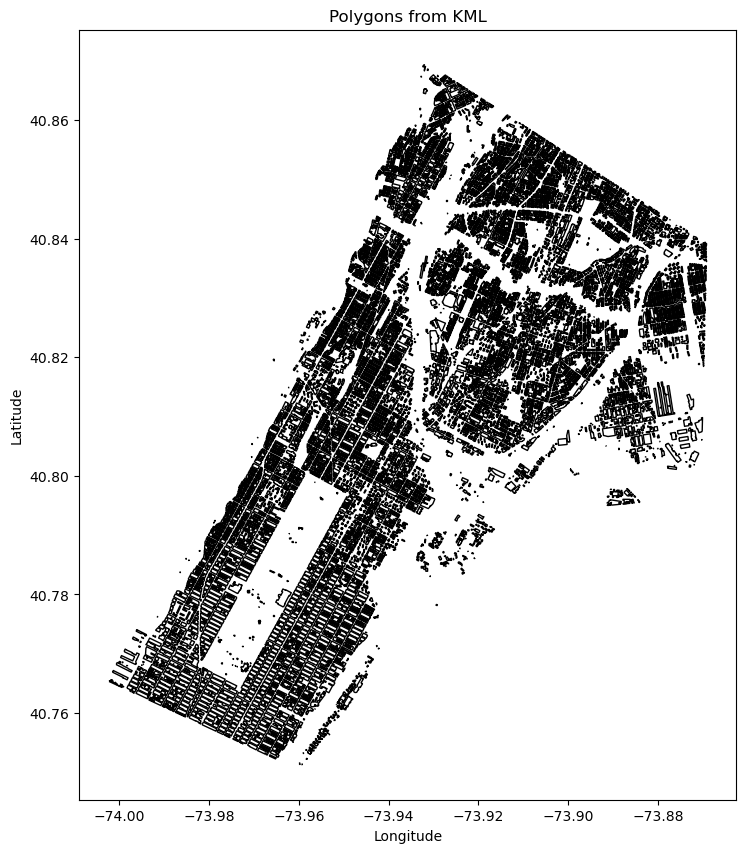

In [79]:
# Convert DataFrame to a GeoDataFrame with the appropriate CRS (WGS84)
buildings_gdf = gpd.GeoDataFrame(kml_data, geometry="geometry", crs="EPSG:4326")

# Plot the GeoDataFrame
buildings_gdf.plot(edgecolor="black", facecolor="none", figsize=(10, 10))
plt.title("Polygons from KML")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [80]:
main_gdf=filtered_final_gdf
main_gdf.head()

,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,...,AOT_diff,AOT_ratio,WVP_diff,WVP_ratio,visual_diff,visual_ratio,SCL_diff,SCL_ratio,red_diff,red_ratio,green_diff,green_ratio,blue_diff,blue_ratio,nir08_diff,nir08_ratio,swir16_diff,swir16_ratio,swir22_diff,swir22_ratio,coastal_diff,coastal_ratio,emis_diff,emis_ratio,emsd_diff,emsd_ratio,trad_diff,trad_ratio,urad_diff,urad_ratio,atran_diff,atran_ratio,cdist_diff,cdist_ratio,lwir11_diff,lwir11_ratio,Wind_Solar_Impact,Temp_Humidity_Ratio,Wind_Dir_Radians,Wind_U_Component,Wind_V_Component,Green_Heat_Reflection,Urban_Water_Buffer,Temp_Humidity_Diff,Temp_Solar_Impact,Wind_Temperature_Ratio,NDVI_NDBI_Ratio,Wind_Direction_Speed_Impact,geometry,index_right
0,-73.933025,40.862807,391.0,263.0,387.0,261.0,678.0,2202.0,2691.0,2146.0,2861.0,3219.0,1443.0,704.0,144.0,1736.0,27.0,4.0,397.552083,368.0,488.5,426.5,802.7500,2372.90625,2962.90625,1880.0,3101.12500,3622.020833,1599.68750,834.00000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.792828,0.037806,0.051707,...,3.0,1.021277,-1094.5,0.613319,-16.5,0.620690,0.0,1.0,-0.001856,0.950876,-0.005582,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.074328,0.830103,1381.646154,0.616207,2.357537,2.189086,-2.194972,862.508651,0.136023,-17.123077,12253.110059,0.112759,-3.998098,418.738462,POINT (-8230186.711 4992126.787),9670
1,-73.932935,40.862807,384.0,263.0,387.0,261.0,763.0,2225.0,2702.0,2146.0,2860.0,3168.0,1485.0,767.0,144.0,1736.0,27.0,4.0,392.656250,368.0,488.5,426.5,841.7500,2343.96875,2934.96875,1880.0,3104.12500,3580.562500,1651.56250,903.50000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.819300,0.037806,0.051708,...,3.0,1.021277,-1094.5,0.613319,-16.5,0.620690,0.0,1.0,-0.001856,0.950876,-0.005583,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.052872,0.830850,1381.646154,0.616207,2.357537,2.189086,-2.194972,868.856723,0.126417,-17.123077,12253.110059,0.112759,-4.301897,418.738462,POINT (-8230176.718 4992126.787),9670
2,-73.932846,40.862807,377.0,402.0,550.0,520.0,832.0,2207.0,2684.0,2056.0,2826.0,3117.0,1503.0,816.0,144.0,1736.0,53.0,4.0,387.760417,471.0,573.0,548.0,906.8125,2350.59375,2892.34375,2202.0,3107.75000,3539.104167,1684.59375,954.59375,141.0,2830.5,56.0,4.0,0.036042,0.046061,0.028947,0.269508,0.129358,0.069381,0.027764,0.9831,0.0069,8.855333,1.037,0.8503,0.17,24.845773,0.039516,0.052093,...,3.0,1.021277,-1094.5,0.613319,-3.0,0.946429,0.0,1.0,-0.003474,0.912059,-0.006032,0.884195,-0.005248,0.846503,0.006105,1.023174,0.003085,1.024420,0.006192,1.097976,-0.003451,0.889409,0.0005,1.000508,0.0,0.999855,-0.491167,0.947449,-2.228,0.317611,0.2378,1.388243,-1.068333,0.137281,-5.031415,0.831597,1381.646154,0.616207,2.357537,2.189086,-2.194972,694.124840,0.089794,-17.123077,12253.110059,0.112759,-3.837498,418.738462,POINT (-8230166.725 4992126.787),9671
3,-73.932756,40.862807,370.0,741.0,894.0,820.0,887.0,2147.0,2636.0,2064.0,2757.0,3067.0,1499.0,849.0,144.0,1736.0,84.0,4.0,382.864583,727.0,887.0,819.0,997.9375,2392.78125,2835.03125,2428.0,3112.000

In [81]:
buildings_gdf.head()

,tessellate,extrude,visibility,id,fid,layer,path,coordinates,geometry
0,-1,0,-1,cugir009034.3,7624,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.919029,40.848199 -73.919329,40.847953 -73....","POLYGON ((-73.91903 40.84820, -73.91933 40.847..."
1,-1,0,-1,cugir009034.4,7625,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.921952,40.849629 -73.921911,40.849679 -73....","POLYGON ((-73.92195 40.84963, -73.92191 40.849..."
2,-1,0,-1,cugir009034.5,7626,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.920502,40.850113 -73.920453,40.850167 -73....","POLYGON ((-73.92050 40.85011, -73.92045 40.850..."
3,-1,0,-1,cugir009034.6,7627,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.92056,40.851403 -73.920531,40.851445 -73.9...","POLYGON ((-73.92056 40.85140, -73.92053 40.851..."
4,-1,0,-1,cugir009034.142,7829,clip_Bronx,/Users/killo/Desktop/Clip_Bronx.kml|layername=...,"-73.912343,40.852184 -73.912472,40.852098 -73....","POLYGON ((-73.91234 40.85218, -73.91247 40.852..."


Instead of a direct one-to-one join, the building layer is summarised into features that describe the built environment around each pixel:

- **Distance to the nearest building:** the minimum distance from each pixel to any building polygon. Shorter distances usually mean denser urban areas, where temperatures can be higher.
- **Building density and morphology:** the number, size, perimeter and compactness of the buildings within a fixed radius around each pixel. A high count indicates a densely built-up area.

In [82]:
print(main_gdf.crs)
print(buildings_gdf.crs)
buildings_gdf = buildings_gdf.to_crs(epsg=3857)
print(buildings_gdf.crs)

EPSG:3857
EPSG:4326
EPSG:3857


In [83]:
# main_gdf (pixels) and buildings_gdf (footprints) are GeoDataFrames in EPSG:3857

# 1. Keep only the geometry column of buildings_gdf
buildings_gdf = buildings_gdf[['geometry']]

# Drop leftover join columns ("index_left", "index_right") that would clash with the next join
for col in ["index_left", "index_right"]:
    if col in main_gdf.columns:
        main_gdf = main_gdf.drop(columns=[col])
    if col in buildings_gdf.columns:
        buildings_gdf = buildings_gdf.drop(columns=[col])

# 2. Remember the original columns of main_gdf
original_columns = list(main_gdf.columns)

# 3. Process main_gdf in chunks so that the join does not run out of memory
chunk_size = 150000  # rows per chunk; adjust to the available memory
chunks = []

for start in range(0, len(main_gdf), chunk_size):
    end = start + chunk_size
    print(f"Processing chunk from {start} to {end}...")
    chunk = main_gdf.iloc[start:end].copy()
    # Nearest-neighbour spatial join: distance from every pixel to the closest building
    joined_chunk = gpd.sjoin_nearest(chunk, buildings_gdf, how="left", distance_col="nearest_building_distance")
    # Keep the original columns plus the new "nearest_building_distance" column
    joined_chunk = joined_chunk[original_columns + ["nearest_building_distance"]]
    chunks.append(joined_chunk)
    # Free the temporary variables
    del chunk, joined_chunk
    gc.collect()

# 4. Combine the chunks into one GeoDataFrame
joined_gdf = pd.concat(chunks, ignore_index=True)

# 5. Free the intermediate variables
del chunks, original_columns
gc.collect()

Processing chunk from 0 to 150000...
Processing chunk from 150000 to 300000...
Processing chunk from 300000 to 450000...
Processing chunk from 450000 to 600000...
Processing chunk from 600000 to 750000...


0

In [84]:
joined_gdf.head()

,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,...,AOT_diff,AOT_ratio,WVP_diff,WVP_ratio,visual_diff,visual_ratio,SCL_diff,SCL_ratio,red_diff,red_ratio,green_diff,green_ratio,blue_diff,blue_ratio,nir08_diff,nir08_ratio,swir16_diff,swir16_ratio,swir22_diff,swir22_ratio,coastal_diff,coastal_ratio,emis_diff,emis_ratio,emsd_diff,emsd_ratio,trad_diff,trad_ratio,urad_diff,urad_ratio,atran_diff,atran_ratio,cdist_diff,cdist_ratio,lwir11_diff,lwir11_ratio,Wind_Solar_Impact,Temp_Humidity_Ratio,Wind_Dir_Radians,Wind_U_Component,Wind_V_Component,Green_Heat_Reflection,Urban_Water_Buffer,Temp_Humidity_Diff,Temp_Solar_Impact,Wind_Temperature_Ratio,NDVI_NDBI_Ratio,Wind_Direction_Speed_Impact,geometry,nearest_building_distance
0,-73.933025,40.862807,391.0,263.0,387.0,261.0,678.0,2202.0,2691.0,2146.0,2861.0,3219.0,1443.0,704.0,144.0,1736.0,27.0,4.0,397.552083,368.0,488.5,426.5,802.7500,2372.90625,2962.90625,1880.0,3101.12500,3622.020833,1599.68750,834.00000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.792828,0.037806,0.051707,...,3.0,1.021277,-1094.5,0.613319,-16.5,0.620690,0.0,1.0,-0.001856,0.950876,-0.005582,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.074328,0.830103,1381.646154,0.616207,2.357537,2.189086,-2.194972,862.508651,0.136023,-17.123077,12253.110059,0.112759,-3.998098,418.738462,POINT (-8230186.711 4992126.787),123.705659
1,-73.932935,40.862807,384.0,263.0,387.0,261.0,763.0,2225.0,2702.0,2146.0,2860.0,3168.0,1485.0,767.0,144.0,1736.0,27.0,4.0,392.656250,368.0,488.5,426.5,841.7500,2343.96875,2934.96875,1880.0,3104.12500,3580.562500,1651.56250,903.50000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.819300,0.037806,0.051708,...,3.0,1.021277,-1094.5,0.613319,-16.5,0.620690,0.0,1.0,-0.001856,0.950876,-0.005583,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.052872,0.830850,1381.646154,0.616207,2.357537,2.189086,-2.194972,868.856723,0.126417,-17.123077,12253.110059,0.112759,-4.301897,418.738462,POINT (-8230176.718 4992126.787),123.945956
2,-73.932846,40.862807,377.0,402.0,550.0,520.0,832.0,2207.0,2684.0,2056.0,2826.0,3117.0,1503.0,816.0,144.0,1736.0,53.0,4.0,387.760417,471.0,573.0,548.0,906.8125,2350.59375,2892.34375,2202.0,3107.75000,3539.104167,1684.59375,954.59375,141.0,2830.5,56.0,4.0,0.036042,0.046061,0.028947,0.269508,0.129358,0.069381,0.027764,0.9831,0.0069,8.855333,1.037,0.8503,0.17,24.845773,0.039516,0.052093,...,3.0,1.021277,-1094.5,0.613319,-3.0,0.946429,0.0,1.0,-0.003474,0.912059,-0.006032,0.884195,-0.005248,0.846503,0.006105,1.023174,0.003085,1.024420,0.006192,1.097976,-0.003451,0.889409,0.0005,1.000508,0.0,0.999855,-0.491167,0.947449,-2.228,0.317611,0.2378,1.388243,-1.068333,0.137281,-5.031415,0.831597,1381.646154,0.616207,2.357537,2.189086,-2.194972,694.124840,0.089794,-17.123077,12253.110059,0.112759,-3.837498,418.738462,POINT (-8230166.725 4992126.787),124.879885
3,-73.932756,40.862807,370.0,741.0,894.0,820.0,887.0,2147.0,2636.0,2064.0,2757.0,3067.0,1499.0,849.0,144.0,1736.0,84.0,4.0,382.864583,727.0,887.0,819.0,997.9375,2392.

In [85]:
main_gdf = joined_gdf
print(main_gdf.crs)
print(buildings_gdf.crs)


EPSG:3857
EPSG:3857


In [86]:
start_time = time.time()

# buildings_gdf is in EPSG:3857; keep only its geometry column
buildings_gdf = buildings_gdf[['geometry']].copy()

# 1.1 Basic metrics: footprint area, perimeter and compactness (1 = circle)
buildings_gdf['building_area'] = buildings_gdf.geometry.area
buildings_gdf['perimeter'] = buildings_gdf.geometry.length
buildings_gdf['compactness'] = (4 * np.pi * buildings_gdf['building_area']) / (buildings_gdf['perimeter'] ** 2)

# 1.2 Convex hull and solidity (footprint area / convex hull area)
convex_hulls = buildings_gdf.geometry.convex_hull
buildings_gdf['convex_area'] = convex_hulls.area
buildings_gdf['solidity'] = buildings_gdf['building_area'] / buildings_gdf['convex_area']

# 1.3 Minimum rotated rectangle: length-to-width ratio and orientation
try:
    from shapely import minimum_rotated_rectangle as mrr_vectorized
    min_rects = mrr_vectorized(buildings_gdf.geometry.values)
except ImportError:
    min_rects = buildings_gdf.geometry.apply(lambda x: x.minimum_rotated_rectangle)

def get_mrr_features(poly):
    """
    For a minimum rotated rectangle, return:
      - the length-to-width ratio: longest side / shortest side
      - the rotation angle: angle between the longest side and the x-axis, in degrees within [0, 180)
    Returns np.nan when the polygon has too few coordinates.
    """
    try:
        coords = np.array(poly.exterior.coords)
    except AttributeError:
        return np.nan, np.nan
    if coords.shape[0] < 5:
        return np.nan, np.nan
    diffs = coords[1:5] - coords[0:4]
    dists = np.sqrt((diffs ** 2).sum(axis=1))
    long_side = dists.max()
    short_side = dists.min() if dists.min() != 0 else np.nan
    long_width_ratio = long_side / short_side if short_side != 0 else np.nan
    max_index = dists.argmax()
    pt1 = coords[max_index]
    pt2 = coords[max_index+1]
    dx, dy = pt2 - pt1
    angle = np.degrees(np.arctan2(dy, dx))
    if angle < 0:
        angle += 180
    return long_width_ratio, angle

vec_get_mrr_features = np.vectorize(get_mrr_features, otypes=[np.float64, np.float64])
lwr, rot_angle = vec_get_mrr_features(min_rects)
buildings_gdf['long_width_ratio'] = lwr
buildings_gdf['rotation_angle'] = rot_angle

# Free the temporary variables of step 1
del convex_hulls, min_rects, vec_get_mrr_features, lwr, rot_angle
buildings_gdf.drop(columns=['convex_area'], inplace=True)
gc.collect()

print("STEP 1 completed in {:.2f} seconds".format(time.time() - start_time))
buildings_gdf.head(5)

STEP 1 completed in 6.85 seconds


,geometry,building_area,perimeter,compactness,solidity,long_width_ratio,rotation_angle
0,"POLYGON ((-8228628.668 4989976.769, -8228662.0...",1084.769028,162.669560,0.515151,0.962275,3.361315,47.286730
1,"POLYGON ((-8228954.055 4990187.212, -8228949.4...",166.755216,55.834582,0.672176,1.000000,2.224346,148.179116
2,"POLYGON ((-8228792.642 4990258.440, -8228787.1...",247.275876,70.691131,0.621816,1.000000,2.675106,145.989467
3,"POLYGON ((-8228799.098 4990448.286, -8228795.8...",139.449689,54.288967,0.594572,1.000000,2.907809,152.422749
4,"POLYGON ((-8227884.386 4990563.225, -8227898.7...",378.297884,77.809612,0.785195,1.000000,1.035365,131.225678


In [87]:
import dask_geopandas as dgp

start_time = time.time()

# main_gdf is in EPSG:3857. Radius (metres) of the buffer in which the buildings are aggregated.
buffer_radius = 100

# Spatial index of buildings_gdf, built once (the per-building metrics come from step 1)
sindex = buildings_gdf.sindex

def aggregate_buildings(buffer_geom):
    """
    Find the buildings that intersect buffer_geom and compute:
      - building_count: number of buildings
      - total_building_area: total footprint area
      - avg_building_area: mean footprint area
      - total_building_perimeter: total perimeter
      - avg_building_perimeter: mean perimeter
      - std_building_area: standard deviation of the footprint area
      - avg_building_compactness: mean compactness
      - total_building_compactness: sum of the compactness values
      - building_density: number of buildings / buffer area
      - building_coverage_ratio: total footprint area / buffer area
      - area_to_perimeter_ratio: mean footprint area / mean perimeter
    """
    possible_idx = list(sindex.query(buffer_geom, predicate='intersects'))
    if len(possible_idx) == 0:
        return pd.Series({
            'building_count': 0,
            'total_building_area': 0,
            'avg_building_area': 0,
            'total_building_perimeter': 0,
            'avg_building_perimeter': 0,
            'std_building_area': 0,
            'avg_building_compactness': 0,
            'total_building_compactness': 0,
            'building_density': 0,
            'building_coverage_ratio': 0,
            'area_to_perimeter_ratio': 0
        })
    selected = buildings_gdf.iloc[possible_idx]
    selected = selected[selected.geometry.intersects(buffer_geom)]
    if selected.empty:
        return pd.Series({
            'building_count': 0,
            'total_building_area': 0,
            'avg_building_area': 0,
            'total_building_perimeter': 0,
            'avg_building_perimeter': 0,
            'std_building_area': 0,
            'avg_building_compactness': 0,
            'total_building_compactness': 0,
            'building_density': 0,
            'building_coverage_ratio': 0,
            'area_to_perimeter_ratio': 0
        })
    building_count = len(selected)
    total_building_area = selected['building_area'].sum()
    avg_building_area = selected['building_area'].mean()
    total_building_perimeter = selected['perimeter'].sum()
    avg_building_perimeter = selected['perimeter'].mean()
    std_building_area = selected['building_area'].std() if building_count > 1 else 0
    avg_building_compactness = selected['compactness'].mean()
    total_building_compactness = selected['compactness'].sum()
    buffer_area = buffer_geom.area
    building_density = building_count / buffer_area if buffer_area > 0 else 0
    building_coverage_ratio = total_building_area / buffer_area if buffer_area > 0 else 0
    area_to_perimeter_ratio = avg_building_area / avg_building_perimeter if avg_building_perimeter > 0 else 0

    return pd.Series({
        'building_count': building_count,
        'total_building_area': total_building_area,
        'avg_building_area': avg_building_area,
        'total_building_perimeter': total_building_perimeter,
        'avg_building_perimeter': avg_building_perimeter,
        'std_building_area': std_building_area,
        'avg_building_compactness': avg_building_compactness,
        'total_building_compactness': total_building_compactness,
        'building_density': building_density,
        'building_coverage_ratio': building_coverage_ratio,
        'area_to_perimeter_ratio': area_to_perimeter_ratio
    })

def process_main_partition(df):
    df = df.copy()
    df['buffer'] = df.geometry.buffer(buffer_radius)
    metrics = df.apply(lambda row: aggregate_buildings(row['buffer']), axis=1)
    df = df.join(metrics)
    df = df.drop(columns=['buffer'])
    return df

# Convert main_gdf to a dask-geopandas object split into 10 partitions
d_main = dgp.from_geopandas(main_gdf, npartitions=10)
d_main = d_main.map_partitions(process_main_partition)
main_gdf_with_metrics = d_main.compute()

del sindex, d_main
gc.collect()

print("STEP 2 completed in {:.2f} seconds".format(time.time() - start_time))
main_gdf_with_metrics.head(5)

STEP 2 completed in 1447.99 seconds


,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,...,green_ratio,blue_diff,blue_ratio,nir08_diff,nir08_ratio,swir16_diff,swir16_ratio,swir22_diff,swir22_ratio,coastal_diff,coastal_ratio,emis_diff,emis_ratio,emsd_diff,emsd_ratio,trad_diff,trad_ratio,urad_diff,urad_ratio,atran_diff,atran_ratio,cdist_diff,cdist_ratio,lwir11_diff,lwir11_ratio,Wind_Solar_Impact,Temp_Humidity_Ratio,Wind_Dir_Radians,Wind_U_Component,Wind_V_Component,Green_Heat_Reflection,Urban_Water_Buffer,Temp_Humidity_Diff,Temp_Solar_Impact,Wind_Temperature_Ratio,NDVI_NDBI_Ratio,Wind_Direction_Speed_Impact,geometry,nearest_building_distance,building_count,total_building_area,avg_building_area,total_building_perimeter,avg_building_perimeter,std_building_area,avg_building_compactness,total_building_compactness,building_density,building_coverage_ratio,area_to_perimeter_ratio
0,-73.933025,40.862807,391.0,263.0,387.0,261.0,678.0,2202.0,2691.0,2146.0,2861.0,3219.0,1443.0,704.0,144.0,1736.0,27.0,4.0,397.552083,368.0,488.5,426.5,802.7500,2372.90625,2962.90625,1880.0,3101.12500,3622.020833,1599.68750,834.00000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.792828,0.037806,0.051707,...,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.074328,0.830103,1381.646154,0.616207,2.357537,2.189086,-2.194972,862.508651,0.136023,-17.123077,12253.110059,0.112759,-3.998098,418.738462,POINT (-8230186.711 4992126.787),123.705659,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-73.932935,40.862807,384.0,263.0,387.0,261.0,763.0,2225.0,2702.0,2146.0,2860.0,3168.0,1485.0,767.0,144.0,1736.0,27.0,4.0,392.656250,368.0,488.5,426.5,841.7500,2343.96875,2934.96875,1880.0,3104.12500,3580.562500,1651.56250,903.50000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.819300,0.037806,0.051708,...,0.892020,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.052872,0.830850,1381.646154,0.616207,2.357537,2.189086,-2.194972,868.856723,0.126417,-17.123077,12253.110059,0.112759,-4.301897,418.738462,POINT (-8230176.718 4992126.787),123.945956,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-73.932846,40.862807,377.0,402.0,550.0,520.0,832.0,2207.0,2684.0,2056.0,2826.0,3117.0,1503.0,816.0,144.0,1736.0,53.0,4.0,387.760417,471.0,573.0,548.0,906.8125,2350.59375,2892.34375,2202.0,3107.75000,3539.104167,1684.59375,954.59375,141.0,2830.5,56.0,4.0,0.036042,0.046061,0.028947,0.269508,0.129358,0.069381,0.027764,0.9831,0.0069,8.855333,1.037,0.8503,0.17,24.845773,0.039516,0.052093,...,0.884195,-0.005248,0.846503,0.006105,1.023174,0.003085,1.024420,0.006192,1.097976,-0.003451,0.889409,0.0005,1.000508,0.0,0.999855,-0.491167,0.947449,-2.228,0.317611,0.2378,1.388243,-1.068333,0.137281,-5.031415,0.831597,1381.646154,0.616207,2.357537,2.189086,-2.194972,694.124840,0.089794,-17.123077,12253.110059,0.112759,-3.837498,418.738462,POINT (-8230166.725 4992126.787),124.879885,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-73.932756,40.862807,370.0,741.0,894.0,820.0,887.0,2147.0,2636.0,2064.0,2757.0,3067.0,1499.0,849.0,144.0,1736.0,84.0,4.0,382.864583,727.0,887.0,819.0,997

In [88]:
# Ratio of the MODIS NDVI to the building coverage (a coverage of 0 becomes NaN to avoid dividing by zero)
main_gdf_with_metrics['building_coverage_ratio'] = main_gdf_with_metrics['building_coverage_ratio'].replace(0, np.nan)

main_gdf_with_metrics['NDVI_Building_Ratio'] = main_gdf_with_metrics['NDVI_mean'] / main_gdf_with_metrics['building_coverage_ratio']

In [90]:
final_data = main_gdf_with_metrics
final_data.head()

,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,...,blue_diff,blue_ratio,nir08_diff,nir08_ratio,swir16_diff,swir16_ratio,swir22_diff,swir22_ratio,coastal_diff,coastal_ratio,emis_diff,emis_ratio,emsd_diff,emsd_ratio,trad_diff,trad_ratio,urad_diff,urad_ratio,atran_diff,atran_ratio,cdist_diff,cdist_ratio,lwir11_diff,lwir11_ratio,Wind_Solar_Impact,Temp_Humidity_Ratio,Wind_Dir_Radians,Wind_U_Component,Wind_V_Component,Green_Heat_Reflection,Urban_Water_Buffer,Temp_Humidity_Diff,Temp_Solar_Impact,Wind_Temperature_Ratio,NDVI_NDBI_Ratio,Wind_Direction_Speed_Impact,geometry,nearest_building_distance,building_count,total_building_area,avg_building_area,total_building_perimeter,avg_building_perimeter,std_building_area,avg_building_compactness,total_building_compactness,building_density,building_coverage_ratio,area_to_perimeter_ratio,NDVI_Building_Ratio
0,-73.933025,40.862807,391.0,263.0,387.0,261.0,678.0,2202.0,2691.0,2146.0,2861.0,3219.0,1443.0,704.0,144.0,1736.0,27.0,4.0,397.552083,368.0,488.5,426.5,802.7500,2372.90625,2962.90625,1880.0,3101.12500,3622.020833,1599.68750,834.00000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.792828,0.037806,0.051707,...,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.074328,0.830103,1381.646154,0.616207,2.357537,2.189086,-2.194972,862.508651,0.136023,-17.123077,12253.110059,0.112759,-3.998098,418.738462,POINT (-8230186.711 4992126.787),123.705659,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN
1,-73.932935,40.862807,384.0,263.0,387.0,261.0,763.0,2225.0,2702.0,2146.0,2860.0,3168.0,1485.0,767.0,144.0,1736.0,27.0,4.0,392.656250,368.0,488.5,426.5,841.7500,2343.96875,2934.96875,1880.0,3104.12500,3580.562500,1651.56250,903.50000,141.0,2830.5,43.5,4.0,0.035950,0.046125,0.029020,0.264283,0.130440,0.070682,0.027782,0.9834,0.0055,8.851000,1.037,0.8503,0.18,24.819300,0.037806,0.051708,...,-0.004386,0.868674,0.009130,1.035778,0.004634,1.036824,0.007012,1.110121,-0.003300,0.893802,0.0007,1.000711,0.0,0.999818,-0.490500,0.947492,-2.228,0.317611,0.2378,1.388243,-1.065000,0.144578,-5.052872,0.830850,1381.646154,0.616207,2.357537,2.189086,-2.194972,868.856723,0.126417,-17.123077,12253.110059,0.112759,-4.301897,418.738462,POINT (-8230176.718 4992126.787),123.945956,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN
2,-73.932846,40.862807,377.0,402.0,550.0,520.0,832.0,2207.0,2684.0,2056.0,2826.0,3117.0,1503.0,816.0,144.0,1736.0,53.0,4.0,387.760417,471.0,573.0,548.0,906.8125,2350.59375,2892.34375,2202.0,3107.75000,3539.104167,1684.59375,954.59375,141.0,2830.5,56.0,4.0,0.036042,0.046061,0.028947,0.269508,0.129358,0.069381,0.027764,0.9831,0.0069,8.855333,1.037,0.8503,0.17,24.845773,0.039516,0.052093,...,-0.005248,0.846503,0.006105,1.023174,0.003085,1.024420,0.006192,1.097976,-0.003451,0.889409,0.0005,1.000508,0.0,0.999855,-0.491167,0.947449,-2.228,0.317611,0.2378,1.388243,-1.068333,0.137281,-5.031415,0.831597,1381.646154,0.616207,2.357537,2.189086,-2.194972,694.124840,0.089794,-17.123077,12253.110059,0.112759,-3.837498,418.738462,POINT (-8230166.725 4992126.787),124.879885,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN
3,-73.932756,40.862807,370.0,741.0,894.0,820.0,887.0,2147.0,2636.0,2064.0,2757.0,3067.0,1499.0,849.0,144.0,1736.0,84.0,4.0,382.864583,727.0,887.0,819.0,997.9375,2

In [91]:
final_data.shape

(621109, 179)

## 7. Focal (100 m neighbourhood) features
For every pixel, the mean of selected features over all pixels within 100 m is added as `buffered_<feature>`.

In [92]:
# Features whose 100 m neighbourhood mean is added as buffered_<feature>
buffered_features = [
    # Sentinel-2 bands (single day)
    "B01_single", "B02_single", "B03_single", "B04_single", "B05_single", "B06_single", "B07_single",
    "B08_single", "B8A_single", "B09_single", "B11_single", "B12_single","AOT_single","WVP_single","visual_single",
    "SCL_single",

    # Landsat bands (single scene)
    'red_single','green_single','blue_single','nir08_single','swir16_single','swir22_single','coastal_single','emis_single','emsd_single',
    'trad_single','urad_single','atran_single','cdist_single','lwir11_single',

    # Vegetation, water and built-up indices (single day)
    "NDVI_single",'NDVI_single_lst',"NDBI_single", "NDBIa_single", "NDWI_single", "NDTI_single", "Albedo_single",
    'Albedo_NYC_single',"EVI_single", "BSR_single",

    # Weather interaction features
    "Wind_Solar_Impact", "Temp_Humidity_Ratio", "Wind_Dir_Radians", "Wind_U_Component",
    "Wind_V_Component", "Green_Heat_Reflection", "Urban_Water_Buffer", "Temp_Humidity_Diff",
    "Temp_Solar_Impact", "Wind_Temperature_Ratio", "NDVI_NDBI_Ratio", "Wind_Direction_Speed_Impact",

    # MODIS composites
    'LST_mean','Emis_31_mean','Emis_32_mean','NDVI_mean','EVI_mean'
]

In [94]:
final_data.crs

<Projected CRS: EPSG:3857>
Name: WGS 84 / Pseudo-Mercator
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: World between 85.06°S and 85.06°N.
- bounds: (-180.0, -85.06, 180.0, 85.06)
Coordinate Operation:
- name: Popular Visualisation Pseudo-Mercator
- method: Popular Visualisation Pseudo Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [98]:
import dask
from dask import delayed
from dask.distributed import Client, LocalCluster

# Local Dask cluster that leaves about 30% of the RAM to the system:
# 32 GB * 70% ≈ 22.4 GB shared by 4 workers, i.e. about 5.6 GB per worker
cluster = LocalCluster(n_workers=4, threads_per_worker=1, memory_limit="5.6GB")
client = Client(cluster)
print("Dask client created:", client)

def process_chunk(chunk, buffered_features, buffer_radius):
    """
    Add 100 m focal means to one chunk of pixels:
      1. create a buffer around every pixel and aggregate all target features with one spatial join
      2. average every feature inside each buffer -> new column 'buffered_{feature}'
      3. drop the temporary buffer column and return the chunk
    Neighbours are searched within the same chunk only.
    """
    # Work on a copy so the input is not modified
    chunk = chunk.copy()

    # Buffer around every pixel (computed once)
    chunk['buffer'] = chunk.geometry.buffer(buffer_radius)

    # GeoDataFrame that holds only the buffers; the original index becomes the group key
    buffered_df = chunk[['buffer']].reset_index().rename(columns={'index': 'buffer_index'})
    buffered_df = buffered_df.set_geometry('buffer')

    # GeoDataFrame with every target feature plus the geometry
    feat_df = chunk[buffered_features + ['geometry']]

    # A single spatial join: which pixels fall inside each buffer
    joined = gpd.sjoin(buffered_df, feat_df, how='left', predicate='intersects')

    # Mean of every target feature per buffer (buffer_index)
    agg = joined.groupby('buffer_index')[buffered_features].mean()

    # Map the means back onto the chunk
    for feature in buffered_features:
        chunk[f'buffered_{feature}'] = chunk.index.map(agg[feature])

    # Drop the temporary buffer column
    chunk.drop(columns=['buffer'], inplace=True)

    return chunk

# final_data is a GeoDataFrame in EPSG:3857 with a geometry column

# Buffer radius
buffer_radius = 100  # metres

start_time = time.time()

# Split final_data into small chunks to limit the memory used by each task
chunk_size = 10000
delayed_chunks = []
n = len(final_data)
for start in range(0, n, chunk_size):
    end = start + chunk_size
    chunk = final_data.iloc[start:end]
    delayed_chunk = delayed(process_chunk)(chunk, buffered_features, buffer_radius)
    delayed_chunks.append(delayed_chunk)

# dask.compute runs the tasks in parallel on the 4 workers of the LocalCluster
processed_chunks = dask.compute(*delayed_chunks)

# Combine the processed chunks into the final result
final_gdf = pd.concat(processed_chunks, ignore_index=True)

print("Completed in {:.2f} seconds".format(time.time() - start_time))
final_gdf.sample(5)

Dask client created: <Client: 'tcp://127.0.0.1:51719' processes=4 threads=4, memory=20.86 GiB>
Completed in 94.40 seconds


,Longitude,Latitude,B01_single,B02_single,B03_single,B04_single,B05_single,B06_single,B07_single,B08_single,B8A_single,B09_single,B11_single,B12_single,AOT_single,WVP_single,visual_single,SCL_single,B01_median,B02_median,B03_median,B04_median,B05_median,B06_median,B07_median,B08_median,B8A_median,B09_median,B11_median,B12_median,AOT_median,WVP_median,visual_median,SCL_median,red_single,green_single,blue_single,nir08_single,swir16_single,swir22_single,coastal_single,emis_single,emsd_single,trad_single,urad_single,atran_single,cdist_single,lwir11_single,red_median,green_median,...,buffered_B08_single,buffered_B8A_single,buffered_B09_single,buffered_B11_single,buffered_B12_single,buffered_AOT_single,buffered_WVP_single,buffered_visual_single,buffered_SCL_single,buffered_red_single,buffered_green_single,buffered_blue_single,buffered_nir08_single,buffered_swir16_single,buffered_swir22_single,buffered_coastal_single,buffered_emis_single,buffered_emsd_single,buffered_trad_single,buffered_urad_single,buffered_atran_single,buffered_cdist_single,buffered_lwir11_single,buffered_NDVI_single,buffered_NDVI_single_lst,buffered_NDBI_single,buffered_NDBIa_single,buffered_NDWI_single,buffered_NDTI_single,buffered_Albedo_single,buffered_Albedo_NYC_single,buffered_EVI_single,buffered_BSR_single,buffered_Wind_Solar_Impact,buffered_Temp_Humidity_Ratio,buffered_Wind_Dir_Radians,buffered_Wind_U_Component,buffered_Wind_V_Component,buffered_Green_Heat_Reflection,buffered_Urban_Water_Buffer,buffered_Temp_Humidity_Diff,buffered_Temp_Solar_Impact,buffered_Wind_Temperature_Ratio,buffered_NDVI_NDBI_Ratio,buffered_Wind_Direction_Speed_Impact,buffered_LST_mean,buffered_Emis_31_mean,buffered_Emis_32_mean,buffered_NDVI_mean,buffered_EVI_mean
85228,-73.923869,40.835604,1264.0,656.0,686.0,1038.0,1367.0,1784.0,1626.0,1228.0,1916.0,2234.0,2272.0,2140.0,144.0,1631.0,106.0,5.0,1281.687500,1182.0,1389.0,1626.0,1761.06250,1877.62500,1951.21875,1739.0,2022.75000,2285.322917,2527.37500,2375.65625,141.0,2662.0,165.5,5.000,0.191178,0.175641,0.138039,0.238708,0.279316,0.268197,0.115562,0.9637,0.010167,9.770667,1.035,0.8505,1.880000,33.427088,0.160772,0.148718,...,2518.234310,2592.970711,2316.192469,2757.020921,2592.276151,144.0,1888.100418,165.807531,5.041841,0.194726,0.181035,0.149943,0.267775,0.280591,0.254322,0.131767,0.963408,0.009758,9.740479,1.035,0.850500,1.890781,33.489486,0.166174,0.198904,0.054455,-0.111719,-0.196642,0.054219,2206.671597,2194.748452,0.480366,1.199836,1381.646154,0.616207,2.357537,2.189086,-2.194972,262.924565,-0.003699,-17.123077,12253.110059,0.112759,-0.266092,418.738462,29.837070,0.491515,0.491854,0.218347,0.124183
392494,-73.965790,40.800411,1604.0,2108.0,2254.0,2170.0,2082.0,2030.0,2137.0,2644.0,2132.0,2150.0,2551.0,2186.0,144.0,1924.0,221.0,5.0,1639.916667,1839.0,2019.0,2184.0,2112.28125,2129.46875,2178.84375,2298.0,2199.46875,2253.625000,2549.06250,2325.15625,141.0,2712.5,222.5,5.000,0.191985,0.173771,0.151487,0.227222,0.248057,0.218302,0.131173,0.9577,0.015300,9.642000,1.034,0.8507,0.693333,32.818937,0.183510,0.166511,...,2156.358289,2195.732620,2171.636364,2543.550802,2368.229947,144.0,1784.117647,174.368984,5.331551,0.181690,0.167367,0.140877,0.228978,0.251211,0.230156,0.125453,0.968046,0.011013,9.709066,1.034,0.850699,0.692276,32.849543,0.095880,0.119077,0.100356,0.004476,-0.134042,0.040809,1988.824270,1975.726631,0.560157,1.259329,1299.253846,0.553293,2.985856,0.456973,-2.910498,157.392510,-0.015911,-21.600000,11798.446154,0.110121,2.481259,504.018935,27.274280,0.496000,0.494781,0.183063,0.097948
51932,-73.915790,40.841889,630.0,724.0,623.0,493.0,558.0,611.0,539.0,448.0,500.0,386.0,384.0,372.0,144.0,1924.0,51.0,3.0,1546.868056,2078.0,1997.0,2093.0,2616.15625,2872.75000,2938.87500,2217.0,2793.31250,2164.888889,3121.90625,2913.46875,141.0,2781.5,213.5,6.625,0.202912,0.184050,0.138983,0.253267,0.284486,0.241549,0.114099,0.9599,0.011500,9.647778,1.036,0.8505,1.726667,33.975082,0.198854,0.180602,...,428.679803,431.187192,371.635468,341.59605

In [99]:
final_gdf.shape

(621109, 236)

In [100]:
final_gdf.crs

<Projected CRS: EPSG:3857>
Name: WGS 84 / Pseudo-Mercator
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: World between 85.06°S and 85.06°N.
- bounds: (-180.0, -85.06, 180.0, 85.06)
Coordinate Operation:
- name: Popular Visualisation Pseudo-Mercator
- method: Popular Visualisation Pseudo Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

## 8. Attach pixel features to the training and submission points
Every point takes the inverse-distance-weighted mean of its 5 nearest pixels. The mapped columns are prefixed with `mapped_`.

In [101]:
ground_gdf.head()

,Longitude,Latitude,datetime,UHI Index,geometry
0,-73.909167,40.813107,24-07-2021 15:53,1.030289,POINT (-8227530.799 4984813.901)
1,-73.909187,40.813045,24-07-2021 15:53,1.030289,POINT (-8227533.025 4984804.830)
2,-73.909215,40.812978,24-07-2021 15:53,1.023798,POINT (-8227536.179 4984795.024)
3,-73.909242,40.812908,24-07-2021 15:53,1.023798,POINT (-8227539.148 4984784.729)
4,-73.909257,40.812845,24-07-2021 15:53,1.021634,POINT (-8227540.817 4984775.414)


In [102]:
ground_gdf=ground_gdf[["Longitude","Latitude","UHI Index","geometry"]]
ground_gdf.head()

,Longitude,Latitude,UHI Index,geometry
0,-73.909167,40.813107,1.030289,POINT (-8227530.799 4984813.901)
1,-73.909187,40.813045,1.030289,POINT (-8227533.025 4984804.830)
2,-73.909215,40.812978,1.023798,POINT (-8227536.179 4984795.024)
3,-73.909242,40.812908,1.023798,POINT (-8227539.148 4984784.729)
4,-73.909257,40.812845,1.021634,POINT (-8227540.817 4984775.414)


In [103]:
test_gdf.head()

,Longitude,Latitude,UHI Index,geometry
0,-73.971665,40.788763,NaN,POINT (-8234488.081 4981234.054)
1,-73.971928,40.788875,NaN,POINT (-8234517.395 4981250.473)
2,-73.967080,40.789080,NaN,POINT (-8233977.681 4981280.614)
3,-73.972550,40.789082,NaN,POINT (-8234586.599 4981280.860)
4,-73.969697,40.787953,NaN,POINT (-8234268.967 4981114.961)


In [105]:
from sklearn.neighbors import NearestNeighbors

def k_weight_mapping(points_gdf, final_gdf, k=5, attributes=None):
    """
    Map the attributes of final_gdf onto points_gdf with k-nearest-neighbour
    inverse-distance weighting.

    Parameters:
      points_gdf: GeoDataFrame of the points to map onto (point geometries).
      final_gdf: GeoDataFrame that provides the attributes (point geometries).
      k: number of neighbours, 5 by default.
      attributes: names of the attributes to map. None maps every non-geometry column of final_gdf.

    Returns:
      a copy of points_gdf with the mapped attributes, named "mapped_{attr}".
    """
    # Copy the inputs so the originals are not modified
    points_gdf = points_gdf.copy()
    final_gdf = final_gdf.copy()

    # Point coordinates of both layers
    point_coords = np.array([[pt.x, pt.y] for pt in points_gdf.geometry])
    final_coords = np.array([[pt.x, pt.y] for pt in final_gdf.geometry])

    # k nearest pixels of every point
    nn = NearestNeighbors(n_neighbors=k, metric='euclidean')
    nn.fit(final_coords)
    distances, indices = nn.kneighbors(point_coords)

    # Inverse-distance weights. If a point coincides with some pixels (distance 0),
    # those pixels get weight 1 and the others weight 0.
    weights = np.zeros_like(distances)
    for i in range(len(distances)):
        if np.any(distances[i] == 0):
            weights[i] = (distances[i] == 0).astype(float)
        else:
            weights[i] = 1.0 / distances[i]
        # Normalise so that every row sums to 1
        weights[i] = weights[i] / weights[i].sum()

    # By default, map every column of final_gdf except the geometry
    if attributes is None:
        attributes = [col for col in final_gdf.columns if col != 'geometry']

    # Weighted mean of every attribute over the k neighbours
    for attr in attributes:
        # Attribute values of final_gdf
        attr_values = final_gdf[attr].values
        # Values of the k neighbours of every point, shape (n_points, k)
        mapped_vals = np.array([attr_values[idx] for idx in indices])
        # Weighted mean, stored as a new column
        points_gdf[f'mapped_{attr}'] = (mapped_vals * weights).sum(axis=1)

    return points_gdf

gc.collect()

# Number of neighbours
k = 5

# Map the pixel features onto the training points
ground_mapped = k_weight_mapping(ground_gdf, final_gdf, k=k, attributes=None)

print("Mapped Ground Data:")
ground_mapped.head()

Mapped Ground Data:


,Longitude,Latitude,UHI Index,geometry,mapped_Longitude,mapped_Latitude,mapped_B01_single,mapped_B02_single,mapped_B03_single,mapped_B04_single,mapped_B05_single,mapped_B06_single,mapped_B07_single,mapped_B08_single,mapped_B8A_single,mapped_B09_single,mapped_B11_single,mapped_B12_single,mapped_AOT_single,mapped_WVP_single,mapped_visual_single,mapped_SCL_single,mapped_B01_median,mapped_B02_median,mapped_B03_median,mapped_B04_median,mapped_B05_median,mapped_B06_median,mapped_B07_median,mapped_B08_median,mapped_B8A_median,mapped_B09_median,mapped_B11_median,mapped_B12_median,mapped_AOT_median,mapped_WVP_median,mapped_visual_median,mapped_SCL_median,mapped_red_single,mapped_green_single,mapped_blue_single,mapped_nir08_single,mapped_swir16_single,mapped_swir22_single,mapped_coastal_single,mapped_emis_single,mapped_emsd_single,mapped_trad_single,mapped_urad_single,mapped_atran_single,...,mapped_buffered_B08_single,mapped_buffered_B8A_single,mapped_buffered_B09_single,mapped_buffered_B11_single,mapped_buffered_B12_single,mapped_buffered_AOT_single,mapped_buffered_WVP_single,mapped_buffered_visual_single,mapped_buffered_SCL_single,mapped_buffered_red_single,mapped_buffered_green_single,mapped_buffered_blue_single,mapped_buffered_nir08_single,mapped_buffered_swir16_single,mapped_buffered_swir22_single,mapped_buffered_coastal_single,mapped_buffered_emis_single,mapped_buffered_emsd_single,mapped_buffered_trad_single,mapped_buffered_urad_single,mapped_buffered_atran_single,mapped_buffered_cdist_single,mapped_buffered_lwir11_single,mapped_buffered_NDVI_single,mapped_buffered_NDVI_single_lst,mapped_buffered_NDBI_single,mapped_buffered_NDBIa_single,mapped_buffered_NDWI_single,mapped_buffered_NDTI_single,mapped_buffered_Albedo_single,mapped_buffered_Albedo_NYC_single,mapped_buffered_EVI_single,mapped_buffered_BSR_single,mapped_buffered_Wind_Solar_Impact,mapped_buffered_Temp_Humidity_Ratio,mapped_buffered_Wind_Dir_Radians,mapped_buffered_Wind_U_Component,mapped_buffered_Wind_V_Component,mapped_buffered_Green_Heat_Reflection,mapped_buffered_Urban_Water_Buffer,mapped_buffered_Temp_Humidity_Diff,mapped_buffered_Temp_Solar_Impact,mapped_buffered_Wind_Temperature_Ratio,mapped_buffered_NDVI_NDBI_Ratio,mapped_buffered_Wind_Direction_Speed_Impact,mapped_buffered_LST_mean,mapped_buffered_Emis_31_mean,mapped_buffered_Emis_32_mean,mapped_buffered_NDVI_mean,mapped_buffered_EVI_mean
0,-73.909167,40.813107,1.030289,POINT (-8227530.799 4984813.901),-73.909166,40.813104,1063.838697,923.099277,1057.380464,1057.608231,1143.573203,1706.959593,1970.868528,1942.319895,2065.274047,2084.053240,1487.433276,1075.000234,144.0,2004.226849,107.911123,4.432081,1054.603320,1070.518982,1179.480906,1272.819841,1237.296247,1822.360185,2006.699001,1864.612568,2090.740000,2117.573332,1625.243944,1249.743457,141.0,2623.565772,129.795082,4.782399,0.096381,0.087985,0.066335,0.180486,0.146332,0.115795,0.060577,0.969518,0.008608,9.922326,1.034,0.8507,...,1971.734552,2034.878123,2117.234929,1882.346054,1619.668048,144.0,2003.316993,137.349290,4.629880,0.123994,0.110585,0.088410,0.199016,0.178974,0.151795,0.079781,0.967547,0.007909,9.877052,1.034,0.8507,1.132780,34.435621,0.199455,0.243430,-0.018445,-0.217900,-0.232336,0.088040,1569.221112,1566.691712,1.461678,1.006240,1381.646154,0.616207,2.357537,2.189086,-2.194972,288.504586,0.023290,-17.123077,12253.110059,0.112759,-0.204994,418.738462,-16.358833,0.421069,0.421069,0.416304,0.302909
1,-73.909187,40.813045,1.030289,POINT (-8227533.025 4984804.830),-73.909174,40.813041,1042.959415,784.761390,900.305946,859.963297,1058.470646,1624.990173,1934.478827,1939.429218,2005.132881,2085.419755,1450.194360,1031.165725,144.0,2006.617213,87.957092,4.298682,1033.458413,891.656858,1028.905218,1047.672655,1146.973757,1773.826337,1974.289105,1934.787413,2071.918131,2121.942543,1560.189975,1180.295680,141.0,2653.390355,106.977964,4.769940,0.084045,0.078595,0.057035,0.179824,0.137544,0.104160,0.051656,0.970537,0.009183,9.909114,1.034,0.8507,...,1980.00

In [106]:
gc.collect()

# Map the pixel features onto the submission points
test_mapped = k_weight_mapping(test_gdf, final_gdf, k=k, attributes=None)

print("Mapped Test Data:")
test_mapped.head()

Mapped Test Data:


,Longitude,Latitude,UHI Index,geometry,mapped_Longitude,mapped_Latitude,mapped_B01_single,mapped_B02_single,mapped_B03_single,mapped_B04_single,mapped_B05_single,mapped_B06_single,mapped_B07_single,mapped_B08_single,mapped_B8A_single,mapped_B09_single,mapped_B11_single,mapped_B12_single,mapped_AOT_single,mapped_WVP_single,mapped_visual_single,mapped_SCL_single,mapped_B01_median,mapped_B02_median,mapped_B03_median,mapped_B04_median,mapped_B05_median,mapped_B06_median,mapped_B07_median,mapped_B08_median,mapped_B8A_median,mapped_B09_median,mapped_B11_median,mapped_B12_median,mapped_AOT_median,mapped_WVP_median,mapped_visual_median,mapped_SCL_median,mapped_red_single,mapped_green_single,mapped_blue_single,mapped_nir08_single,mapped_swir16_single,mapped_swir22_single,mapped_coastal_single,mapped_emis_single,mapped_emsd_single,mapped_trad_single,mapped_urad_single,mapped_atran_single,...,mapped_buffered_B08_single,mapped_buffered_B8A_single,mapped_buffered_B09_single,mapped_buffered_B11_single,mapped_buffered_B12_single,mapped_buffered_AOT_single,mapped_buffered_WVP_single,mapped_buffered_visual_single,mapped_buffered_SCL_single,mapped_buffered_red_single,mapped_buffered_green_single,mapped_buffered_blue_single,mapped_buffered_nir08_single,mapped_buffered_swir16_single,mapped_buffered_swir22_single,mapped_buffered_coastal_single,mapped_buffered_emis_single,mapped_buffered_emsd_single,mapped_buffered_trad_single,mapped_buffered_urad_single,mapped_buffered_atran_single,mapped_buffered_cdist_single,mapped_buffered_lwir11_single,mapped_buffered_NDVI_single,mapped_buffered_NDVI_single_lst,mapped_buffered_NDBI_single,mapped_buffered_NDBIa_single,mapped_buffered_NDWI_single,mapped_buffered_NDTI_single,mapped_buffered_Albedo_single,mapped_buffered_Albedo_NYC_single,mapped_buffered_EVI_single,mapped_buffered_BSR_single,mapped_buffered_Wind_Solar_Impact,mapped_buffered_Temp_Humidity_Ratio,mapped_buffered_Wind_Dir_Radians,mapped_buffered_Wind_U_Component,mapped_buffered_Wind_V_Component,mapped_buffered_Green_Heat_Reflection,mapped_buffered_Urban_Water_Buffer,mapped_buffered_Temp_Humidity_Diff,mapped_buffered_Temp_Solar_Impact,mapped_buffered_Wind_Temperature_Ratio,mapped_buffered_NDVI_NDBI_Ratio,mapped_buffered_Wind_Direction_Speed_Impact,mapped_buffered_LST_mean,mapped_buffered_Emis_31_mean,mapped_buffered_Emis_32_mean,mapped_buffered_NDVI_mean,mapped_buffered_EVI_mean
0,-73.971665,40.788763,NaN,POINT (-8234488.081 4981234.054),-73.971652,40.788768,813.315599,467.909214,619.513058,469.934757,976.833595,2008.343295,2270.905011,2349.770964,2329.936427,2305.099181,1498.136148,963.696705,144.0,1914.464238,48.038880,4.115892,806.861700,578.290639,682.396339,599.151061,1184.306432,2291.495254,2701.160230,2386.233278,2825.717562,2653.938372,1872.006282,1258.082128,141.0,2949.083082,61.354280,4.157468,0.053870,0.064262,0.032370,0.244265,0.142504,0.088931,0.025167,0.954300,0.007800,9.467414,1.034,0.8507,...,2200.367534,2286.768517,2330.880110,1863.384813,1455.366630,144.0,1880.863141,112.023978,4.446078,0.103408,0.099938,0.073585,0.234437,0.182765,0.140766,0.063572,0.955058,0.007407,9.458139,1.034,0.8507,0.682281,31.743431,0.342762,0.399568,-0.067240,-0.410002,-0.339806,0.135135,1579.334837,1581.313494,0.307089,0.919961,1299.253846,0.553293,2.985856,0.456973,-2.910498,500.628807,0.040575,-21.6,11798.446154,0.110121,0.436488,504.018935,-242.721443,0.050015,0.049813,-0.257331,-0.261807
1,-73.971928,40.788875,NaN,POINT (-8234517.395 4981250.473),-73.971920,40.788880,869.525663,617.438420,768.000373,688.765903,1058.110720,2077.590299,2388.933428,2585.283477,2581.712726,2368.880421,1630.743113,1058.690397,144.0,1737.711644,70.239908,4.000000,863.302421,639.023194,776.122357,647.430659,1250.171723,2549.983819,2941.750764,3364.928020,3086.116896,2701.016871,2037.835960,1388.546802,141.0,2933.849733,66.246080,4.000000,0.060204,0.067317,0.040502,0.250493,0.146525,0.091173,0.034225,0.954300,0.007800,9.469180,1.034,0.8507,...,2389.705817,2444.016119,2400.758485,

In [109]:
# Number of missing values per column
print("Ground_mapped NA counts:")
print(ground_mapped.isna().sum())


# Same for test_mapped
print("\nTest_mapped NA counts:")
print(test_mapped.isna().sum())

Ground_mapped NA counts:
Longitude                                        0
Latitude                                         0
UHI Index                                        0
geometry                                         0
mapped_Longitude                                 0
mapped_Latitude                                  0
mapped_B01_single                                0
mapped_B02_single                                0
mapped_B03_single                                0
mapped_B04_single                                0
mapped_B05_single                                0
mapped_B06_single                                0
mapped_B07_single                                0
mapped_B08_single                                0
mapped_B8A_single                                0
mapped_B09_single                                0
mapped_B11_single                                0
mapped_B12_single                                0
mapped_AOT_single                                0
mapped

In [110]:
# Replace every remaining missing value with 0
ground_mapped= ground_mapped.fillna(0)

test_mapped= test_mapped.fillna(0)

In [112]:
# Number of missing values per column
print("Ground_mapped NA counts:")
print(ground_mapped.isna().sum())


# Same for test_mapped
print("\nTest_mapped NA counts:")
print(test_mapped.isna().sum())

Ground_mapped NA counts:
Longitude                                      0
Latitude                                       0
UHI Index                                      0
geometry                                       0
mapped_Longitude                               0
mapped_Latitude                                0
mapped_B01_single                              0
mapped_B02_single                              0
mapped_B03_single                              0
mapped_B04_single                              0
mapped_B05_single                              0
mapped_B06_single                              0
mapped_B07_single                              0
mapped_B08_single                              0
mapped_B8A_single                              0
mapped_B09_single                              0
mapped_B11_single                              0
mapped_B12_single                              0
mapped_AOT_single                              0
mapped_WVP_single                           

In [113]:
ground_mapped.columns.tolist()

['Longitude',
 'Latitude',
 'UHI Index',
 'geometry',
 'mapped_Longitude',
 'mapped_Latitude',
 'mapped_B01_single',
 'mapped_B02_single',
 'mapped_B03_single',
 'mapped_B04_single',
 'mapped_B05_single',
 'mapped_B06_single',
 'mapped_B07_single',
 'mapped_B08_single',
 'mapped_B8A_single',
 'mapped_B09_single',
 'mapped_B11_single',
 'mapped_B12_single',
 'mapped_AOT_single',
 'mapped_WVP_single',
 'mapped_visual_single',
 'mapped_SCL_single',
 'mapped_B01_median',
 'mapped_B02_median',
 'mapped_B03_median',
 'mapped_B04_median',
 'mapped_B05_median',
 'mapped_B06_median',
 'mapped_B07_median',
 'mapped_B08_median',
 'mapped_B8A_median',
 'mapped_B09_median',
 'mapped_B11_median',
 'mapped_B12_median',
 'mapped_AOT_median',
 'mapped_WVP_median',
 'mapped_visual_median',
 'mapped_SCL_median',
 'mapped_red_single',
 'mapped_green_single',
 'mapped_blue_single',
 'mapped_nir08_single',
 'mapped_swir16_single',
 'mapped_swir22_single',
 'mapped_coastal_single',
 'mapped_emis_single',
 'm

In [114]:
# Training table (the geometry is no longer needed)
final_df = pd.DataFrame(ground_mapped.drop(columns='geometry'))
final_df.head()

,Longitude,Latitude,UHI Index,mapped_Longitude,mapped_Latitude,mapped_B01_single,mapped_B02_single,mapped_B03_single,mapped_B04_single,mapped_B05_single,mapped_B06_single,mapped_B07_single,mapped_B08_single,mapped_B8A_single,mapped_B09_single,mapped_B11_single,mapped_B12_single,mapped_AOT_single,mapped_WVP_single,mapped_visual_single,mapped_SCL_single,mapped_B01_median,mapped_B02_median,mapped_B03_median,mapped_B04_median,mapped_B05_median,mapped_B06_median,mapped_B07_median,mapped_B08_median,mapped_B8A_median,mapped_B09_median,mapped_B11_median,mapped_B12_median,mapped_AOT_median,mapped_WVP_median,mapped_visual_median,mapped_SCL_median,mapped_red_single,mapped_green_single,mapped_blue_single,mapped_nir08_single,mapped_swir16_single,mapped_swir22_single,mapped_coastal_single,mapped_emis_single,mapped_emsd_single,mapped_trad_single,mapped_urad_single,mapped_atran_single,mapped_cdist_single,...,mapped_buffered_B08_single,mapped_buffered_B8A_single,mapped_buffered_B09_single,mapped_buffered_B11_single,mapped_buffered_B12_single,mapped_buffered_AOT_single,mapped_buffered_WVP_single,mapped_buffered_visual_single,mapped_buffered_SCL_single,mapped_buffered_red_single,mapped_buffered_green_single,mapped_buffered_blue_single,mapped_buffered_nir08_single,mapped_buffered_swir16_single,mapped_buffered_swir22_single,mapped_buffered_coastal_single,mapped_buffered_emis_single,mapped_buffered_emsd_single,mapped_buffered_trad_single,mapped_buffered_urad_single,mapped_buffered_atran_single,mapped_buffered_cdist_single,mapped_buffered_lwir11_single,mapped_buffered_NDVI_single,mapped_buffered_NDVI_single_lst,mapped_buffered_NDBI_single,mapped_buffered_NDBIa_single,mapped_buffered_NDWI_single,mapped_buffered_NDTI_single,mapped_buffered_Albedo_single,mapped_buffered_Albedo_NYC_single,mapped_buffered_EVI_single,mapped_buffered_BSR_single,mapped_buffered_Wind_Solar_Impact,mapped_buffered_Temp_Humidity_Ratio,mapped_buffered_Wind_Dir_Radians,mapped_buffered_Wind_U_Component,mapped_buffered_Wind_V_Component,mapped_buffered_Green_Heat_Reflection,mapped_buffered_Urban_Water_Buffer,mapped_buffered_Temp_Humidity_Diff,mapped_buffered_Temp_Solar_Impact,mapped_buffered_Wind_Temperature_Ratio,mapped_buffered_NDVI_NDBI_Ratio,mapped_buffered_Wind_Direction_Speed_Impact,mapped_buffered_LST_mean,mapped_buffered_Emis_31_mean,mapped_buffered_Emis_32_mean,mapped_buffered_NDVI_mean,mapped_buffered_EVI_mean
0,-73.909167,40.813107,1.030289,-73.909166,40.813104,1063.838697,923.099277,1057.380464,1057.608231,1143.573203,1706.959593,1970.868528,1942.319895,2065.274047,2084.053240,1487.433276,1075.000234,144.0,2004.226849,107.911123,4.432081,1054.603320,1070.518982,1179.480906,1272.819841,1237.296247,1822.360185,2006.699001,1864.612568,2090.740000,2117.573332,1625.243944,1249.743457,141.0,2623.565772,129.795082,4.782399,0.096381,0.087985,0.066335,0.180486,0.146332,0.115795,0.060577,0.969518,0.008608,9.922326,1.034,0.8507,1.115067,...,1971.734552,2034.878123,2117.234929,1882.346054,1619.668048,144.0,2003.316993,137.349290,4.629880,0.123994,0.110585,0.088410,0.199016,0.178974,0.151795,0.079781,0.967547,0.007909,9.877052,1.034,0.8507,1.132780,34.435621,0.199455,0.243430,-0.018445,-0.217900,-0.232336,0.088040,1569.221112,1566.691712,1.461678,1.006240,1381.646154,0.616207,2.357537,2.189086,-2.194972,288.504586,0.023290,-17.123077,12253.110059,0.112759,-0.204994,418.738462,-16.358833,0.421069,0.421069,0.416304,0.302909
1,-73.909187,40.813045,1.030289,-73.909174,40.813041,1042.959415,784.761390,900.305946,859.963297,1058.470646,1624.990173,1934.478827,1939.429218,2005.132881,2085.419755,1450.194360,1031.165725,144.0,2006.617213,87.957092,4.298682,1033.458413,891.656858,1028.905218,1047.672655,1146.973757,1773.826337,1974.289105,1934.787413,2071.918131,2121.942543,1560.189975,1180.295680,141.0,2653.390355,106.977964,4.769940,0.084045,0.078595,0.057035,0.179824,0.137544,0.104160,0.051656,0.970537,0.009183,9.909114,1.034,0.8507,1.110450,...,1980.005301,2036.419558,2111.431933,1847.654

In [115]:
# Submission table
final_submission = pd.DataFrame(test_mapped.drop(columns='geometry'))
final_submission.head()

,Longitude,Latitude,UHI Index,mapped_Longitude,mapped_Latitude,mapped_B01_single,mapped_B02_single,mapped_B03_single,mapped_B04_single,mapped_B05_single,mapped_B06_single,mapped_B07_single,mapped_B08_single,mapped_B8A_single,mapped_B09_single,mapped_B11_single,mapped_B12_single,mapped_AOT_single,mapped_WVP_single,mapped_visual_single,mapped_SCL_single,mapped_B01_median,mapped_B02_median,mapped_B03_median,mapped_B04_median,mapped_B05_median,mapped_B06_median,mapped_B07_median,mapped_B08_median,mapped_B8A_median,mapped_B09_median,mapped_B11_median,mapped_B12_median,mapped_AOT_median,mapped_WVP_median,mapped_visual_median,mapped_SCL_median,mapped_red_single,mapped_green_single,mapped_blue_single,mapped_nir08_single,mapped_swir16_single,mapped_swir22_single,mapped_coastal_single,mapped_emis_single,mapped_emsd_single,mapped_trad_single,mapped_urad_single,mapped_atran_single,mapped_cdist_single,...,mapped_buffered_B08_single,mapped_buffered_B8A_single,mapped_buffered_B09_single,mapped_buffered_B11_single,mapped_buffered_B12_single,mapped_buffered_AOT_single,mapped_buffered_WVP_single,mapped_buffered_visual_single,mapped_buffered_SCL_single,mapped_buffered_red_single,mapped_buffered_green_single,mapped_buffered_blue_single,mapped_buffered_nir08_single,mapped_buffered_swir16_single,mapped_buffered_swir22_single,mapped_buffered_coastal_single,mapped_buffered_emis_single,mapped_buffered_emsd_single,mapped_buffered_trad_single,mapped_buffered_urad_single,mapped_buffered_atran_single,mapped_buffered_cdist_single,mapped_buffered_lwir11_single,mapped_buffered_NDVI_single,mapped_buffered_NDVI_single_lst,mapped_buffered_NDBI_single,mapped_buffered_NDBIa_single,mapped_buffered_NDWI_single,mapped_buffered_NDTI_single,mapped_buffered_Albedo_single,mapped_buffered_Albedo_NYC_single,mapped_buffered_EVI_single,mapped_buffered_BSR_single,mapped_buffered_Wind_Solar_Impact,mapped_buffered_Temp_Humidity_Ratio,mapped_buffered_Wind_Dir_Radians,mapped_buffered_Wind_U_Component,mapped_buffered_Wind_V_Component,mapped_buffered_Green_Heat_Reflection,mapped_buffered_Urban_Water_Buffer,mapped_buffered_Temp_Humidity_Diff,mapped_buffered_Temp_Solar_Impact,mapped_buffered_Wind_Temperature_Ratio,mapped_buffered_NDVI_NDBI_Ratio,mapped_buffered_Wind_Direction_Speed_Impact,mapped_buffered_LST_mean,mapped_buffered_Emis_31_mean,mapped_buffered_Emis_32_mean,mapped_buffered_NDVI_mean,mapped_buffered_EVI_mean
0,-73.971665,40.788763,0.0,-73.971652,40.788768,813.315599,467.909214,619.513058,469.934757,976.833595,2008.343295,2270.905011,2349.770964,2329.936427,2305.099181,1498.136148,963.696705,144.0,1914.464238,48.038880,4.115892,806.861700,578.290639,682.396339,599.151061,1184.306432,2291.495254,2701.160230,2386.233278,2825.717562,2653.938372,1872.006282,1258.082128,141.0,2949.083082,61.354280,4.157468,0.053870,0.064262,0.032370,0.244265,0.142504,0.088931,0.025167,0.954300,0.007800,9.467414,1.034,0.8507,0.666792,...,2200.367534,2286.768517,2330.880110,1863.384813,1455.366630,144.0,1880.863141,112.023978,4.446078,0.103408,0.099938,0.073585,0.234437,0.182765,0.140766,0.063572,0.955058,0.007407,9.458139,1.034,0.8507,0.682281,31.743431,0.342762,0.399568,-0.067240,-0.410002,-0.339806,0.135135,1579.334837,1581.313494,0.307089,0.919961,1299.253846,0.553293,2.985856,0.456973,-2.910498,500.628807,0.040575,-21.6,11798.446154,0.110121,0.436488,504.018935,-242.721443,0.050015,0.049813,-0.257331,-0.261807
1,-73.971928,40.788875,0.0,-73.971920,40.788880,869.525663,617.438420,768.000373,688.765903,1058.110720,2077.590299,2388.933428,2585.283477,2581.712726,2368.880421,1630.743113,1058.690397,144.0,1737.711644,70.239908,4.000000,863.302421,639.023194,776.122357,647.430659,1250.171723,2549.983819,2941.750764,3364.928020,3086.116896,2701.016871,2037.835960,1388.546802,141.0,2933.849733,66.246080,4.000000,0.060204,0.067317,0.040502,0.250493,0.146525,0.091173,0.034225,0.954300,0.007800,9.469180,1.034,0.8507,0.660000,...,2389.705817,2444.016119,2400.758485,2026.064347,1602.366681,144.0,1861.55

## 9. Clean-up and feature selection
### Remove duplicate rows

In [116]:
final_df.shape

(11229, 238)

In [117]:
column_names = final_df.columns.tolist()

# Columns ignored when looking for duplicate rows (coordinates, join index and target)
columns_to_ignore = ['Longitude', 'Latitude', 'UHI Index', 'mapped_Longitude', 'mapped_Latitude']

# Columns used to detect duplicates
columns_to_check = [x for x in column_names if x not in columns_to_ignore]

# Convert array-valued cells to tuples so that they can be compared
for col in columns_to_check:
    final_df[col] = final_df[col].apply(lambda x: tuple(x) if isinstance(x, np.ndarray) and x.ndim > 0 else x)
final_df = final_df.drop_duplicates(subset=columns_to_check, keep='first')

final_df.dropna(inplace=True)
final_df = final_df[~final_df.isin([np.inf, -np.inf]).any(axis=1)]

In [118]:
final_df.shape

(11229, 238)

### Drop non-feature columns

In [119]:
# Drop the point and pixel coordinates
final_df = final_df.drop(columns=['Longitude','Latitude','mapped_Longitude','mapped_Latitude'])

In [120]:
final_df.shape

(11229, 234)

In [123]:
# Convert object columns to numeric and fill NaNs
object_cols = final_df.select_dtypes(include=['object']).columns
for col in object_cols:
    final_df[col] = pd.to_numeric(final_df[col], errors='coerce')
    # Fill NaN within the loop for each converted column
    final_df[col].fillna(final_df[col].mean(), inplace=True)
    final_df[col] = final_df[col].astype(int)

# Select numerical features and handle NaNs consistently
numerical_features = final_df.select_dtypes(include=['number']).drop(columns=["UHI Index"])
# Replace infinite values with NaN
numerical_features = numerical_features.replace([np.inf, -np.inf], np.nan)

# Fill NaN values with 0 (or consider imputation methods)
numerical_features = numerical_features.fillna(0)  # Or explore other imputation techniques

In [126]:
numerical_features.shape

(11229, 233)

In [127]:
numerical_features.head()

,mapped_B01_single,mapped_B02_single,mapped_B03_single,mapped_B04_single,mapped_B05_single,mapped_B06_single,mapped_B07_single,mapped_B08_single,mapped_B8A_single,mapped_B09_single,mapped_B11_single,mapped_B12_single,mapped_AOT_single,mapped_WVP_single,mapped_visual_single,mapped_SCL_single,mapped_B01_median,mapped_B02_median,mapped_B03_median,mapped_B04_median,mapped_B05_median,mapped_B06_median,mapped_B07_median,mapped_B08_median,mapped_B8A_median,mapped_B09_median,mapped_B11_median,mapped_B12_median,mapped_AOT_median,mapped_WVP_median,mapped_visual_median,mapped_SCL_median,mapped_red_single,mapped_green_single,mapped_blue_single,mapped_nir08_single,mapped_swir16_single,mapped_swir22_single,mapped_coastal_single,mapped_emis_single,mapped_emsd_single,mapped_trad_single,mapped_urad_single,mapped_atran_single,mapped_cdist_single,mapped_lwir11_single,mapped_red_median,mapped_green_median,mapped_blue_median,mapped_nir08_median,...,mapped_buffered_B08_single,mapped_buffered_B8A_single,mapped_buffered_B09_single,mapped_buffered_B11_single,mapped_buffered_B12_single,mapped_buffered_AOT_single,mapped_buffered_WVP_single,mapped_buffered_visual_single,mapped_buffered_SCL_single,mapped_buffered_red_single,mapped_buffered_green_single,mapped_buffered_blue_single,mapped_buffered_nir08_single,mapped_buffered_swir16_single,mapped_buffered_swir22_single,mapped_buffered_coastal_single,mapped_buffered_emis_single,mapped_buffered_emsd_single,mapped_buffered_trad_single,mapped_buffered_urad_single,mapped_buffered_atran_single,mapped_buffered_cdist_single,mapped_buffered_lwir11_single,mapped_buffered_NDVI_single,mapped_buffered_NDVI_single_lst,mapped_buffered_NDBI_single,mapped_buffered_NDBIa_single,mapped_buffered_NDWI_single,mapped_buffered_NDTI_single,mapped_buffered_Albedo_single,mapped_buffered_Albedo_NYC_single,mapped_buffered_EVI_single,mapped_buffered_BSR_single,mapped_buffered_Wind_Solar_Impact,mapped_buffered_Temp_Humidity_Ratio,mapped_buffered_Wind_Dir_Radians,mapped_buffered_Wind_U_Component,mapped_buffered_Wind_V_Component,mapped_buffered_Green_Heat_Reflection,mapped_buffered_Urban_Water_Buffer,mapped_buffered_Temp_Humidity_Diff,mapped_buffered_Temp_Solar_Impact,mapped_buffered_Wind_Temperature_Ratio,mapped_buffered_NDVI_NDBI_Ratio,mapped_buffered_Wind_Direction_Speed_Impact,mapped_buffered_LST_mean,mapped_buffered_Emis_31_mean,mapped_buffered_Emis_32_mean,mapped_buffered_NDVI_mean,mapped_buffered_EVI_mean
0,1063.838697,923.099277,1057.380464,1057.608231,1143.573203,1706.959593,1970.868528,1942.319895,2065.274047,2084.053240,1487.433276,1075.000234,144.0,2004.226849,107.911123,4.432081,1054.603320,1070.518982,1179.480906,1272.819841,1237.296247,1822.360185,2006.699001,1864.612568,2090.740000,2117.573332,1625.243944,1249.743457,141.0,2623.565772,129.795082,4.782399,0.096381,0.087985,0.066335,0.180486,0.146332,0.115795,0.060577,0.969518,0.008608,9.922326,1.034,0.8507,1.115067,34.624173,0.097044,0.090590,0.072388,0.181015,...,1971.734552,2034.878123,2117.234929,1882.346054,1619.668048,144.0,2003.316993,137.349290,4.629880,0.123994,0.110585,0.088410,0.199016,0.178974,0.151795,0.079781,0.967547,0.007909,9.877052,1.034,0.8507,1.132780,34.435621,0.199455,0.243430,-0.018445,-0.217900,-0.232336,0.088040,1569.221112,1566.691712,1.461678,1.006240,1381.646154,0.616207,2.357537,2.189086,-2.194972,288.504586,0.023290,-17.123077,12253.110059,0.112759,-0.204994,418.738462,-16.358833,0.421069,0.421069,0.416304,0.302909
1,1042.959415,784.761390,900.305946,859.963297,1058.470646,1624.990173,1934.478827,1939.429218,2005.132881,2085.419755,1450.194360,1031.165725,144.0,2006.617213,87.957092,4.298682,1033.458413,891.656858,1028.905218,1047.672655,1146.973757,1773.826337,1974.289105,1934.787413,2071.918131,2121.942543,1560.189975,1180.295680,141.0,2653.390355,106.977964,4.769940,0.084045,0.078595,0.057035,0.179824,0.137544,0.104160,0.051656,0.970537,0.009183,9.909114,1.034,0.8507,1.110450,34.560169,0.084774,0.081511,0.063458,0.180167,...,1980.005301,2036.4

### Recursive feature elimination (RFECV)
RFECV (5-fold CV, R² scoring, one feature removed per step) on an 80/20 train/test split with default XGBoost parameters. The run with the tuned parameters (next cell) was not executed for this variant.

In [129]:
X = numerical_features
y = final_df["UHI Index"]

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Base model
xgb_model = XGBRegressor(
    objective='reg:squarederror',
    random_state=42
)

# RFECV picks the number of features automatically, using the R² score
selector_cv = RFECV(estimator=xgb_model, cv=5, scoring='r2', step=1)
selector_cv.fit(X_train, y_train)

# Optimal number of features
print("Optimal number of features: ", selector_cv.n_features_)

# Keep the selected features
X_train_selected = selector_cv.transform(X_train)
X_test_selected = selector_cv.transform(X_test)

# Train the model and evaluate it
xgb_model.fit(X_train_selected, y_train)
print("Test R² score: ", xgb_model.score(X_test_selected, y_test))

# Names of the selected features (X_train is a DataFrame)
selected_features = X_train.columns[selector_cv.support_]
print("Selected features: ", list(selected_features))

Optimal number of features:  58
Test R² score:  0.953273552521153
Selected features:  ['mapped_urad_single', 'mapped_cdist_single', 'mapped_trad_median', 'mapped_urad_median', 'mapped_atran_median', 'mapped_cdist_median', 'mapped_lwir11_median', 'mapped_LST_mean', 'mapped_Emis_31_mean', 'mapped_NDVI_mean', 'mapped_EVI_mean', 'mapped_B01_diff', 'mapped_B01_ratio', 'mapped_B09_diff', 'mapped_WVP_ratio', 'mapped_emis_diff', 'mapped_emis_ratio', 'mapped_emsd_ratio', 'mapped_urad_diff', 'mapped_urad_ratio', 'mapped_atran_diff', 'mapped_atran_ratio', 'mapped_cdist_diff', 'mapped_cdist_ratio', 'mapped_lwir11_diff', 'mapped_lwir11_ratio', 'mapped_building_count', 'mapped_total_building_area', 'mapped_avg_building_perimeter', 'mapped_std_building_area', 'mapped_avg_building_compactness', 'mapped_total_building_compactness', 'mapped_area_to_perimeter_ratio', 'mapped_NDVI_Building_Ratio', 'mapped_buffered_B01_single', 'mapped_buffered_B07_single', 'mapped_buffered_B09_single', 'mapped_buffered_B1

In [ ]:
X = numerical_features
y = final_df["UHI Index"]

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# XGBoost with the tuned hyper-parameters
xgb_model = XGBRegressor(
    colsample_bytree=0.7,
    gamma=0,
    learning_rate=0.04,
    max_depth=15,
    min_child_weight=7,
    n_estimators=800,
    subsample=0.6,
    reg_alpha=0.001,
    reg_lambda=3.5,
    objective='reg:squarederror',
    random_state=42
)

# RFECV picks the number of features automatically, using the R² score
selector_cv = RFECV(estimator=xgb_model, cv=5, scoring='r2', step=1)
selector_cv.fit(X_train, y_train)

# Optimal number of features
print("Optimal number of features: ", selector_cv.n_features_)

# Keep the selected features in the training and test sets
X_train_selected = selector_cv.transform(X_train)
X_test_selected = selector_cv.transform(X_test)

# Train the model and evaluate it
xgb_model.fit(X_train_selected, y_train)
print("Test R² score: ", xgb_model.score(X_test_selected, y_test))

# Names of the selected features (X_train is a DataFrame)
selected_features = X_train.columns[selector_cv.support_]
print("Selected features: ", list(selected_features))

## Outcome
With bilinear resampling and inverse-distance-weighted mapping, RFECV with default XGBoost parameters kept **58 features** and reached a hold-out R² of **0.953**. The same step of the nearest-neighbour pipeline reached **0.955** (`02_uhi_model_nearest.ipynb`), and that pipeline was the one that was tuned and used for the final submission.